![Banner](../../../../Images/Banner/05_geostat/07_simulation.png)

# Sequential Gaussian Co-Simulation (`sgcosim`)

**Dataset:** Jura soil survey, Swiss Jura (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples of seven heavy metals) + prediction grid (`Data/00_shared/data_geostatistics/jura_grid.csv`, 5,957 nodes on a 50 m lattice)

**Target:** Nickel (`Ni`, mg/kg) as the primary variable, chromium (`Cr`, mg/kg) as the secondary variable

**Library:** `geolattice.geostatistics`: `GaussianCoSimulator`, `sgcosim`, `sgcosim_hierarchical`, `sgsim_gpu` (module `geolattice.geostatistics.simulation.sgcosim`, GPU engine `geolattice.geostatistics.gpu.sgs_gpu`)

**Before this notebook:** [Introduction to geostatistical simulation](05_07_00_introduction_geostatistical_sumulations.ipynb), [sequential Gaussian simulation](05_07_01_sgsim.ipynb), and [cokriging](../05_02_kriging/05_02_04_cokriging.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [The multi-Gaussian model and the normal-score transform](#the-multi-gaussian-model-and-the-normal-score-transform)
    - 2.2 [Sequential simulation](#sequential-simulation)
    - 2.3 [Simple kriging of the primary](#simple-kriging-of-the-primary)
    - 2.4 [Cokriging and Markov Model 1](#cokriging-and-markov-model-1)
    - 2.5 [Collocated simple cokriging](#collocated-simple-cokriging)
    - 2.6 [Multi-collocated cokriging and the MM1 nugget diagnostic](#multi-collocated-cokriging-and-the-mm1-nugget-diagnostic)
    - 2.7 [Hierarchical co-simulation](#hierarchical-co-simulation)
    - 2.8 [Ordinary kriging and the GPU engine](#ordinary-kriging-and-the-gpu-engine)
    - 2.9 [The algorithm](#the-algorithm)
3. [Python Setup](#python-setup)
    - 3.1 [CPU and GPU](#cpu-and-gpu)
4. [Jura Data](#jura-data)
    - 4.1 [Prediction and validation sets](#prediction-and-validation-sets)
5. [Normal Scores and the Primary-Secondary Correlation](#normal-scores-and-the-primary-secondary-correlation)
6. [Variogram of the Primary Normal Scores](#variogram-of-the-primary-normal-scores)
7. [An Exhaustive Secondary: Chromium on the Grid](#an-exhaustive-secondary-chromium-on-the-grid)
    - 7.1 [Which $\rho$? The secondary as it exists at the nodes](#which-rho-the-secondary-as-it-exists-at-the-nodes)
8. [Baseline: Plain SGS with `sgsim_gpu`](#baseline-plain-sgs-with-sgsim_gpu)
    - 8.1 [Simple vs ordinary kriging](#simple-vs-ordinary-kriging)
9. [Co-Simulation with `GaussianCoSimulator` and `sgcosim`](#co-simulation-with-gaussiancosimulator-and-sgcosim)
    - 9.1 [How the correlation $\rho$ shapes the realizations](#how-the-correlation-rho-shapes-the-realizations)
10. [Validation at 100 Held-Out Sites](#validation-at-100-held-out-sites)
    - 10.1 [Scanning the input $\rho$](#scanning-the-input-rho)
11. [Reproduction of Histogram, Variogram and Correlation](#reproduction-of-histogram-variogram-and-correlation)
12. [Hierarchical Co-Simulation with `sgcosim_hierarchical`](#hierarchical-co-simulation-with-sgcosim_hierarchical)
13. [Visualization of Spatial Uncertainty](#visualization-of-spatial-uncertainty)
    - 13.1 [Animated display of realizations](#animated-display-of-realizations)
    - 13.2 [Conditional quantile maps (q10, median, q90)](#conditional-quantile-maps-q10-median-q90)
    - 13.3 [Probability of exceeding a threshold](#probability-of-exceeding-a-threshold)
14. [CPU vs GPU Timing](#cpu-vs-gpu-timing)
15. [Summary and Conclusions](#summary-and-conclusions)
    - 15.1 [Choosing the options](#choosing-the-options)
16. [References](#references)

***
## Overview

[Sequential Gaussian simulation](05_07_01_sgsim.ipynb) (SGS) draws maps of one variable that honour its data, its histogram and its variogram. Often a second variable is available that is related to the first: a geophysical survey, a remote-sensing index, a DEM, or another chemical element measured more densely or more cheaply. **Sequential Gaussian co-simulation** uses that secondary variable while it simulates the primary. Each realization then honours the primary data, reproduces the primary histogram and variogram, *and* reproduces the correlation between the two variables. Where the secondary is high, the primary tends to be high in every realization, so the spread between realizations, the uncertainty, shrinks.

The Jura data set (Goovaerts, 1997) is a natural test. Nickel (Ni) and chromium (Cr) come from the same parent rocks and are strongly correlated in the topsoil. This notebook simulates nickel and uses chromium as the secondary variable in the two situations co-simulation is built for:

| Situation | Secondary known… | Function |
|---|---|---|
| **Exhaustive secondary** | at every grid node (here: chromium kriged from all 359 samples, while nickel uses only 259 of them) | `GaussianCoSimulator` / `sgcosim` |
| **Secondary known only at the data** | at the same 359 samples as the primary | `sgcosim_hierarchical` (simulates Cr first, then Ni on each Cr realization) |
| **No secondary** (baseline) | n/a | `sgsim_gpu`, plain SGS on the same engine, on the GPU |

The four objects covered:

| Object | What it does |
|---|---|
| `GaussianCoSimulator` | The engine. `fit(grid, df, ..., secondary=...)` prepares the transform, neighbourhoods and $\rho$; `simulate(nsim, seed)` returns `(nsim, n_nodes)` realizations. CPU or GPU (`use_gpu`). |
| `sgcosim` | One-call wrapper: build, fit and simulate with an exhaustive secondary. |
| `sgcosim_hierarchical` | Joint simulation of two variables known only at the data. Returns `(primary_sims, secondary_sims)`. |
| `sgsim_gpu` | Plain SGS (no secondary) on the same engine with `use_gpu=True`: one CUDA thread per realization. |

This notebook checks, on real data, the properties co-simulation is supposed to have:

1. **Exact conditioning:** the primary data are reproduced in every realization.
2. **Histogram, variogram and correlation reproduction:** the realizations have the Ni histogram and variogram, and carry the Ni-Cr relation.
3. **Better local accuracy than SGS:** at 100 held-out sites, the co-simulated E-type is closer to the truth and the local distributions are narrower but still well calibrated.
4. **Joint reproduction (hierarchical case):** simulated Ni and Cr pairs reproduce the scatter of the data.
5. **CPU = GPU:** the GPU engine gives the same realizations as the CPU engine for the same seed.

One practical lesson comes out of the checks: **$\rho$ must describe the secondary as it is used at the grid nodes.** A kriged Cr map is less informative than a Cr measurement, and using the measurement correlation makes the realizations over-confident (Sections 7 and 10).

***
## Theory

### The multi-Gaussian model and the normal-score transform

SGS and co-simulation assume a **multi-Gaussian random function**: every set of values $\{Y(\mathbf{u}_1), \dots, Y(\mathbf{u}_N)\}$ is jointly Gaussian. Under that model every conditional distribution is Gaussian, with a mean and variance given by simple kriging. Soil metals are skewed, so the data are first mapped to standard normal **normal scores**:

$$
y = G^{-1}\!\bigl(\hat F(z)\bigr),
$$

where $\hat F$ is the empirical cumulative distribution of the data (declustered if needed) and $G$ is the standard normal cdf. The scores have mean 0 and variance 1. Each realization is simulated in normal-score units and mapped back with $z = \hat F^{-1}(G(y))$, interpolated between data values. Beyond the smallest and largest datum the GeoLattice transform extends **linearly** (`tails="linear"`), and `zmin` / `zmax` clip the back-transformed values to physical bounds.

The transform makes each variable Gaussian on its own (univariate normality). The multi-Gaussian model is a stronger assumption than that. It is checked indirectly, through the reproduction tests later in this notebook.

Both variables are transformed separately: $Y_1 = $ normal scores of Ni (primary), $Y_2 = $ normal scores of Cr (secondary). The correlation that matters is the one between the **scores**,

$$
\rho = \operatorname{corr}\bigl(Y_1(\mathbf{u}), Y_2(\mathbf{u})\bigr),
$$

which is close to the rank (Spearman) correlation of the raw values.

### Sequential simulation

Any joint distribution can be factored into a chain of conditionals. With $(n)$ the data and the nodes $\mathbf{u}_1, \dots, \mathbf{u}_N$ visited in a **random order**,

$$
f(y_1, \dots, y_N \mid (n)) \;=\; \prod_{i=1}^{N} f\bigl(y_i \mid (n),\, y_1, \dots, y_{i-1}\bigr).
$$

So a draw from the joint distribution can be built one node at a time: draw $y_1$ from its conditional distribution given the data, add it to the data, draw $y_2$ given the data and $y_1$, and so on. Under the multi-Gaussian model each conditional distribution is

$$
Y(\mathbf{u}_i) \mid \cdot \;\sim\; \mathcal{N}\bigl(y^*_{SK}(\mathbf{u}_i),\; \sigma^2_{SK}(\mathbf{u}_i)\bigr),
$$

the simple-kriging estimate and variance from all conditioning values. In practice only the nearest `num_points` informed locations within `radius` are used (a *neighbourhood*), which is the main approximation of sequential simulation. Each realization uses a new random path and new Gaussian deviates.

### Simple kriging of the primary

With $n$ informed neighbours $\mathbf{u}_\alpha$ (data and previously simulated nodes), covariance $C(\mathbf{h})$ and known mean $m$ (0 for normal scores), simple kriging solves

$$
\mathbf{C}\,\boldsymbol\lambda = \mathbf{c}_0,
\qquad
\mathbf{C}_{\alpha\beta} = C(\mathbf{u}_\alpha - \mathbf{u}_\beta),
\quad
(\mathbf{c}_0)_\alpha = C(\mathbf{u}_\alpha - \mathbf{u}),
$$

$$
y^*_{SK}(\mathbf{u}) = m + \boldsymbol\lambda^\top (\mathbf{y} - m),
\qquad
\sigma^2_{SK}(\mathbf{u}) = C(\mathbf{0}) - \boldsymbol\lambda^\top \mathbf{c}_0 .
$$

The covariance is $C(\mathbf{h}) = C(\mathbf{0}) - \gamma(\mathbf{h})$, built from the GSLIB-style variogram list used throughout `geolattice.geostatistics.simulation`,

```
vario = [azimuth, nugget, major_range, minor_range, sill, vtype]
```

with **practical** ranges. For example, the spherical model with nugget $c_0$, sill $c$ and range $a$ is

$$
\gamma(h) = c_0 + (c - c_0)\left[\tfrac32 \tfrac{h}{a} - \tfrac12 \bigl(\tfrac{h}{a}\bigr)^3\right] \quad (h \le a), \qquad \gamma(h) = c \quad (h > a).
$$

Anisotropy is handled by rotating and rescaling the lag vector by `azimuth`, `major_range` and `minor_range`.

### Cokriging and Markov Model 1

With a secondary variable $Y_2$ the conditional mean of the primary at $\mathbf{u}$ is a **cokriging** estimate:

$$
y_1^*(\mathbf{u}) = \sum_{\alpha} \lambda_\alpha\, y_1(\mathbf{u}_\alpha) + \sum_{\beta} \nu_\beta\, y_2(\mathbf{u}_\beta).
$$

Full cokriging needs three covariances: $C_{11}(\mathbf{h})$, $C_{22}(\mathbf{h})$ and the cross-covariance $C_{12}(\mathbf{h})$, fitted jointly as a positive-definite *linear model of coregionalization*. With an exhaustive secondary it also has to handle thousands of secondary values per node, and the resulting cokriging systems can be badly conditioned.

**Markov Model 1** (MM1; Almeida & Journel, 1994; Journel, 1999) removes most of that. It assumes that the collocated primary value **screens** the secondary from all primary values further away:

$$
E\bigl[Y_2(\mathbf{u}) \mid Y_1(\mathbf{u}) = y,\; Y_1(\mathbf{u}') = y'\bigr] = E\bigl[Y_2(\mathbf{u}) \mid Y_1(\mathbf{u}) = y\bigr]
\quad \text{for all } \mathbf{u}' \ne \mathbf{u}.
$$

Under MM1 the cross-covariance is a rescaled copy of the primary covariance. With $\operatorname{Var}(Y_2) = 1$ and $s = \sqrt{C_{11}(\mathbf{0})}$,

$$
\boxed{\;C_{12}(\mathbf{h}) = \rho\, \frac{C_{11}(\mathbf{h})}{s}\;}
$$

So co-simulation needs only the **primary variogram** and **one number**, $\rho$. The same model fixes the secondary covariance:

$$
C_{22}(\mathbf{h}) = \rho^2\, \frac{C_{11}(\mathbf{h})}{C_{11}(\mathbf{0})} + (1 - \rho^2)\, \delta(\mathbf{h}),
$$

that is, MM1 implies the secondary has the primary's spatial structure plus a **relative nugget of** $1 - \rho^2$. That consequence is testable (Section 2.6).

### Collocated simple cokriging

The simplest and most common way to use MM1 is **collocated** cokriging (Xu et al., 1992): keep only the secondary value *at the node being simulated*, $y_2(\mathbf{u})$. That is what GSLIB `sgsim` does with a secondary, and it is the default here (`secondary_neighbors=1`). With $n$ primary neighbours, the $(n+1)\times(n+1)$ system is

$$
\begin{bmatrix}
\mathbf{C}_{11} & \rho\,\mathbf{c}_0 / s \\[2pt]
\rho\,\mathbf{c}_0^\top / s & 1
\end{bmatrix}
\begin{bmatrix}
\boldsymbol\lambda \\ \nu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\ \rho\, s
\end{bmatrix},
$$

where $\mathbf{C}_{11}$ and $\mathbf{c}_0$ are the primary covariances among the neighbours and to the node, as in simple kriging. The estimate and the cokriging variance are

$$
y_1^*(\mathbf{u}) = \boldsymbol\lambda^\top \mathbf{y}_1 + \nu\, y_2(\mathbf{u}),
\qquad
\sigma^2_{CK}(\mathbf{u}) = C_{11}(\mathbf{0}) - \boldsymbol\lambda^\top \mathbf{c}_0 - \nu\, \rho\, s,
$$

and the simulated value is $y_1(\mathbf{u}) = y_1^*(\mathbf{u}) + \sigma_{CK}(\mathbf{u})\, w$ with $w \sim \mathcal{N}(0,1)$.

Three limits make the role of $\rho$ concrete:

* **$\rho = 0$:** $\nu = 0$ and the system is simple kriging. Co-simulation becomes plain SGS.
* **No primary neighbours** (far from all data, early in the path): $\nu = \rho\, s$ and $\sigma^2_{CK} = C_{11}(\mathbf{0})(1-\rho^2)$. The primary is the secondary rescaled by $\rho$ plus noise with variance reduced by $1 - \rho^2$.
* **$|\rho| \to 1$:** $\sigma^2_{CK} \to 0$ and the primary becomes a rescaled copy of the secondary.

The variance reduction $1 - \rho^2$ is the headline: with $\rho = 0.70$ (Ni against *measured* Cr in Jura) the local variance far from data would drop by about half. Section 7 shows why the effective $\rho$ for a kriged secondary map is smaller.

### Multi-collocated cokriging and the MM1 nugget diagnostic

Collocated cokriging ignores the secondary at every other node. That is fine when the secondary is **at least as continuous** as the primary (seismic, a DEM, or, as here, a kriged map), because its neighbouring values carry little extra information. When the secondary is **noisy**, ignoring its neighbours makes the realized correlation fall short of $\rho$.

`secondary_neighbors = m > 1` uses the secondary at the $m$ nearest nodes with the full MM1 covariances:

$$
\operatorname{Cov}(Y_{1,\alpha}, Y_{1,\beta}) = C_{11}(\mathbf{h}_{\alpha\beta}),\quad
\operatorname{Cov}(Y_{1,\alpha}, Y_{2,b}) = \rho\, \frac{C_{11}(\mathbf{h}_{\alpha b})}{s},\quad
\operatorname{Cov}(Y_{2,a}, Y_{2,b}) = \rho^2\, \frac{C_{11}(\mathbf{h}_{ab})}{C_{11}(\mathbf{0})} + (1-\rho^2)\,[a = b].
$$

That is exact *if MM1 holds*, but it over-fits a smooth secondary, whose real covariance has almost no nugget. To choose, `GaussianCoSimulator.fit` computes

$$
\texttt{mm1\_nugget\_ratio\_} = \frac{\hat\gamma_{22}(h_1) - \rho^2\, \gamma_{11}(h_1) / C_{11}(\mathbf{0})}{1 - \rho^2},
$$

where $\hat\gamma_{22}(h_1)$ is the experimental semivariogram of the secondary scores between each node and its nearest neighbour, and $\gamma_{11}(h_1)$ is the primary model at the same lag. Under MM1 the ratio is 1.

* **Near or above 1:** the secondary is as noisy as MM1 says; `secondary_neighbors > 1` restores $\rho$.
* **Well below 1** (smooth secondary): keep `secondary_neighbors = 1`.

### Hierarchical co-simulation

If the secondary is known **only at the data**, there is nothing to condition on at the grid nodes. The joint distribution of the two scores at all nodes can still be factored as

$$
f(\mathbf{y}_1, \mathbf{y}_2 \mid \text{data}) = f(\mathbf{y}_2 \mid \text{data})\; f(\mathbf{y}_1 \mid \mathbf{y}_2, \text{data}),
$$

which gives a two-step algorithm (`sgcosim_hierarchical`):

1. Simulate the secondary $\mathbf{y}_2^{(\ell)}$ by SGS from its own data and variogram (`vario_secondary`).
2. Simulate the primary by collocated co-simulation on **that** realization, $\mathbf{y}_1^{(\ell)} \mid \mathbf{y}_2^{(\ell)}$, with `vario_primary` and $\rho$ estimated from the data scores.

Each pair $(\mathbf{y}_1^{(\ell)}, \mathbf{y}_2^{(\ell)})$ is one joint realization. Both are back-transformed with their own tables. Paired realizations are what a joint question needs, for example the probability that *both* metals exceed their thresholds at the same place.

### Ordinary kriging and the GPU engine

Without a secondary, `kriging_type="ordinary"` replaces simple kriging by ordinary kriging, which re-estimates the local mean from the neighbours:

$$
\begin{bmatrix} \mathbf{C} & \mathbf{1} \\ \mathbf{1}^\top & 0 \end{bmatrix}
\begin{bmatrix} \boldsymbol\lambda \\ \mu \end{bmatrix}
=
\begin{bmatrix} \mathbf{c}_0 \\ 1 \end{bmatrix},
\qquad
\sigma^2_{OK} = C(\mathbf{0}) - \boldsymbol\lambda^\top \mathbf{c}_0 - \mu .
$$

It is robust to a trend in the mean, but its variance is larger than the simple-kriging variance, which tends to inflate the variance of the realizations. Collocated MM1 cokriging is a simple-kriging system, so `ordinary` is only available without a secondary.

Nodes **within** one realization cannot be simulated in parallel, because each node depends on the ones before it. **Realizations**, however, are independent. The GPU engine (`use_gpu=True`, and `sgsim_gpu`) runs **one CUDA thread per realization**. Each thread walks its own random path, gathers its informed neighbours, builds the (co)kriging system, solves it by Gaussian elimination with partial pivoting, and draws the value. The host generates every realization's random path and Gaussian deviates in exactly the order the CPU engine consumes them, so **GPU realizations equal CPU realizations up to floating-point rounding**. Limits: `num_points` ≤ 48; spherical, exponential and Gaussian variograms; collocated secondary only. Realizations are batched to fit the free GPU memory. The engine warns and falls back to the CPU if the GPU runs out of memory.

### The algorithm

For each realization $\ell = 1, \dots, L$:

1. Normal-score transform the primary data (`itrans=True`) and the exhaustive secondary at the grid nodes. Estimate $\rho$ from the collocated scores at the data, unless it is given.
2. Draw a random path through the grid nodes.
3. At each node $\mathbf{u}$ on the path:
    1. if $\mathbf{u}$ coincides with a datum, copy the datum;
    2. otherwise, take the `num_points` nearest informed locations within `radius`, build the collocated (or multi-collocated) cokriging system, and solve it for $y_1^*$ and $\sigma^2_{CK}$;
    3. draw $y_1(\mathbf{u}) = y_1^* + \sigma_{CK}\, w$ and add it to the conditioning set.
4. Back-transform the realization to Ni units and clip to `zmin` / `zmax`.

***
## Python Setup

### CPU and GPU

`GaussianCoSimulator(..., use_gpu=False|'auto'|True)` and `sgsim_gpu(..., use_gpu=True)` choose the engine:

| Value | Behaviour |
|---|---|
| `False` (default for `GaussianCoSimulator`) | CPU (NumPy), one realization after another. |
| `'auto'` | GPU when CuPy can run a kernel on this card, otherwise CPU. |
| `True` (default for `sgsim_gpu`) | GPU. Falls back to the CPU with a warning when CuPy is missing or the GPU runs out of memory. |

The setup cell probes the GPU once with `cupy_gpu_usable()` and stores the result in `USE_GPU`. Because the GPU and CPU engines give the same realizations, the large runs below use `use_gpu=USE_GPU` and the notebook runs unchanged on a machine without a GPU, only more slowly. Section 14 times the two engines.

Install with `pip install geolattice[geostatistics]` (CPU) or `pip install geolattice[geostatistics-gpu]` / `cupy-cuda13x` (GPU).

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist
from scipy.stats import norm, spearmanr

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    GaussianCoSimulator,
    OrdinaryKriging,
    Variogram,
    sgcosim,
    sgcosim_hierarchical,
    sgsim_gpu,
)
from geolattice.geostatistics.gslib.nscore import nscore_forward
from geolattice.geostatistics.utils.backend import CUPY_AVAILABLE, cupy_gpu_usable

print("pygstat version:", pygstat.__version__)

# cupy_gpu_usable() runs a real kernel, not just `import cupy`
USE_GPU = cupy_gpu_usable()
if USE_GPU:
    import cupy as cp
    name = cp.cuda.runtime.getDeviceProperties(0)["name"]
    name = name.decode() if isinstance(name, bytes) else name
    print(f"CuPy            : {cp.__version__}")
    print(f"GPU (CuPy)      : {name}")
    print("Backend         : GPU (CuPy): one CUDA thread per realization")
else:
    print("CuPy            :", "installed, but cannot run a kernel here" if CUPY_AVAILABLE
          else "not installed  (pip install geolattice[geostatistics-gpu]  or  cupy-cuda13x)")
    print("Backend         : CPU (NumPy)")
print(f"use_gpu         : {USE_GPU}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44
CuPy            : 14.2.0
GPU (CuPy)      : NVIDIA RTX A5500 Laptop GPU
Backend         : GPU (CuPy): one CUDA thread per realization
use_gpu         : True


***
## Jura Data

The Jura data (Atteia et al., 1994; Goovaerts, 1997) are 359 topsoil samples from a 14.5 km² area of the Swiss Jura, analysed for seven heavy metals, with land use and rock type at each site. `jura_grid.csv` holds 5,957 nodes on a 50 m lattice, with land use and rock type but **no** metal values. Coordinates are in kilometres.

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
df_all = pd.read_csv(DATA + "jura_data.csv", index_col=0)
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
grid = grid_df[["Xloc", "Yloc"]].to_numpy(dtype=float)
print(f"jura_data.csv : {len(df_all)} samples, columns {list(df_all.columns)}")
print(f"jura_grid.csv : {len(grid)} nodes, columns {list(grid_df.columns)}")
df_all[["Ni", "Cr", "Co", "Cd", "Zn"]].describe().round(2)

jura_data.csv : 359 samples, columns ['Xloc', 'Yloc', 'Landuse', 'Rock', 'Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']
jura_grid.csv : 5957 nodes, columns ['Xloc', 'Yloc', 'Landuse', 'Rock']


,Ni,Cr,Co,Cd,Zn
count,359.00,359.00,359.00,359.00,359.00
mean,20.02,35.02,9.44,1.29,75.88
std,8.09,10.66,3.57,0.86,30.82
min,1.98,3.32,1.55,0.14,25.00
25%,14.60,27.64,6.66,0.65,54.60
50%,20.68,34.80,9.84,1.10,73.56
75%,25.38,41.46,12.10,1.68,90.00
max,53.20,70.00,20.60,5.13,259.84


The grid is a regular 50 m lattice, so maps are drawn as images. `to_image` places node values on that lattice.

In [3]:
CELL = 0.05  # km
ix = np.rint((grid[:, 0] - grid[:, 0].min()) / CELL).astype(int)
iy = np.rint((grid[:, 1] - grid[:, 1].min()) / CELL).astype(int)
EXTENT = [grid[:, 0].min() - CELL / 2, grid[:, 0].max() + CELL / 2,
          grid[:, 1].min() - CELL / 2, grid[:, 1].max() + CELL / 2]


def to_image(values):
    img = np.full((iy.max() + 1, ix.max() + 1), np.nan)
    img[iy, ix] = values
    return img


def show_map(ax, values, title, cmap="viridis", vmin=None, vmax=None, label="Ni (mg/kg)", points=None):
    im = ax.imshow(to_image(values), origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax)
    if points is not None:
        ax.scatter(points[:, 0], points[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.04)
    return im


print(f"lattice: {ix.max() + 1} x {iy.max() + 1} cells, {len(grid)} inside the study area")

lattice: 97 x 117 cells, 5957 inside the study area


Nickel is nearly symmetric and chromium mildly right-skewed. The two are strongly related, with a few low-Ni / high-Cr samples off the trend. The simulators still transform both to normal scores, because the multi-Gaussian model needs Gaussian *marginals*, not just low skewness.

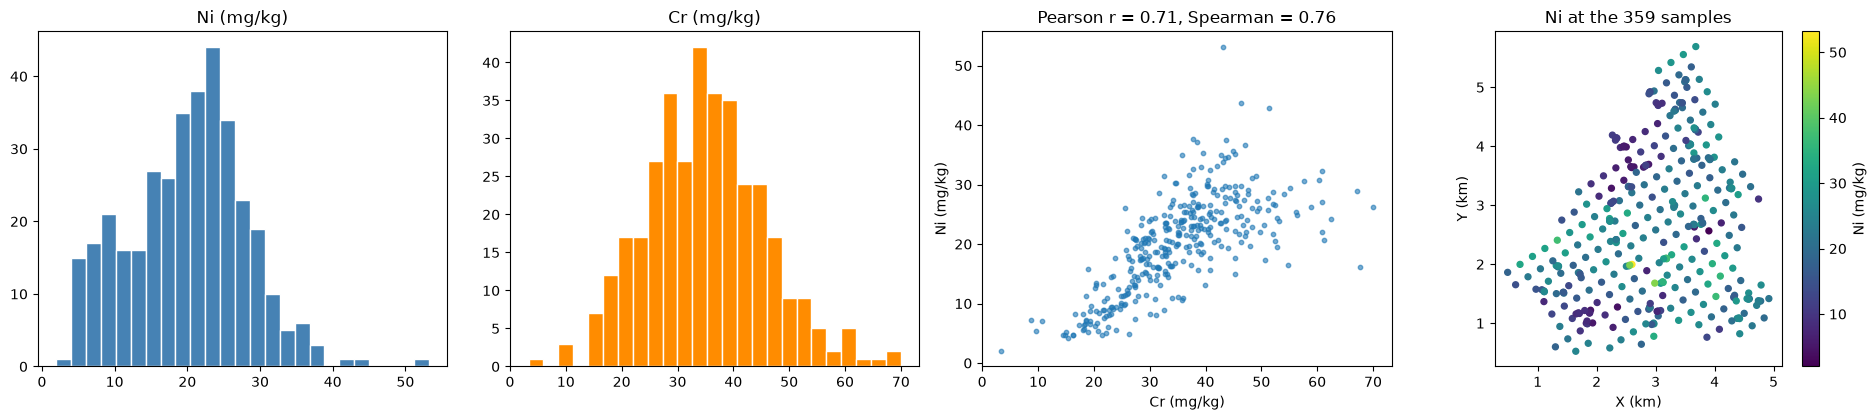

skewness  Ni = 0.11   Cr = 0.30


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
axes[0].hist(df_all["Ni"], bins=25, color="steelblue", edgecolor="w")
axes[0].set_title("Ni (mg/kg)")
axes[1].hist(df_all["Cr"], bins=25, color="darkorange", edgecolor="w")
axes[1].set_title("Cr (mg/kg)")
axes[2].scatter(df_all["Cr"], df_all["Ni"], s=10, alpha=0.6)
axes[2].set_xlabel("Cr (mg/kg)")
axes[2].set_ylabel("Ni (mg/kg)")
r_p = np.corrcoef(df_all["Cr"], df_all["Ni"])[0, 1]
r_s = spearmanr(df_all["Cr"], df_all["Ni"]).correlation
axes[2].set_title(f"Pearson r = {r_p:.2f}, Spearman = {r_s:.2f}")
sc = axes[3].scatter(df_all["Xloc"], df_all["Yloc"], c=df_all["Ni"], s=18, cmap="viridis")
axes[3].set_aspect("equal")
axes[3].set_title("Ni at the 359 samples")
axes[3].set_xlabel("X (km)")
axes[3].set_ylabel("Y (km)")
plt.colorbar(sc, ax=axes[3], label="Ni (mg/kg)")
plt.tight_layout()
plt.show()
print(f"skewness  Ni = {df_all['Ni'].skew():.2f}   Cr = {df_all['Cr'].skew():.2f}")

### Prediction and validation sets

To measure what the secondary variable adds, 100 of the 359 samples are held out at random as a **validation set**. Nickel is used only at the other 259 sites (the **prediction set**); chromium is used at all 359. This is the *undersampled* design of Goovaerts (1997, Chapter 6): the secondary is sampled more densely than the primary, which is the usual reason to co-simulate.

In [5]:
rng_split = np.random.default_rng(359)
test_idx = np.sort(rng_split.choice(len(df_all), size=100, replace=False))
is_test = np.zeros(len(df_all), bool)
is_test[test_idx] = True
df = df_all[~is_test].reset_index(drop=True)      # Ni + Cr: 259 prediction sites
test = df_all[is_test].reset_index(drop=True)     # Ni held out: 100 validation sites
xy_all = df_all[["Xloc", "Yloc"]].to_numpy(float)
xy, xy_test = df[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
print(f"prediction set : {len(df)} sites   Ni mean {df.Ni.mean():.2f}, sd {df.Ni.std():.2f}")
print(f"validation set : {len(test)} sites   Ni mean {test.Ni.mean():.2f}, sd {test.Ni.std():.2f}")

prediction set : 259 sites   Ni mean 20.14, sd 7.75
validation set : 100 sites   Ni mean 19.69, sd 8.96


***
## Normal Scores and the Primary-Secondary Correlation

The simulators transform the data themselves (`itrans=True`). Here the same transform (`nscore_forward`, linear tails) is applied by hand to look at the scores and estimate $\rho$.

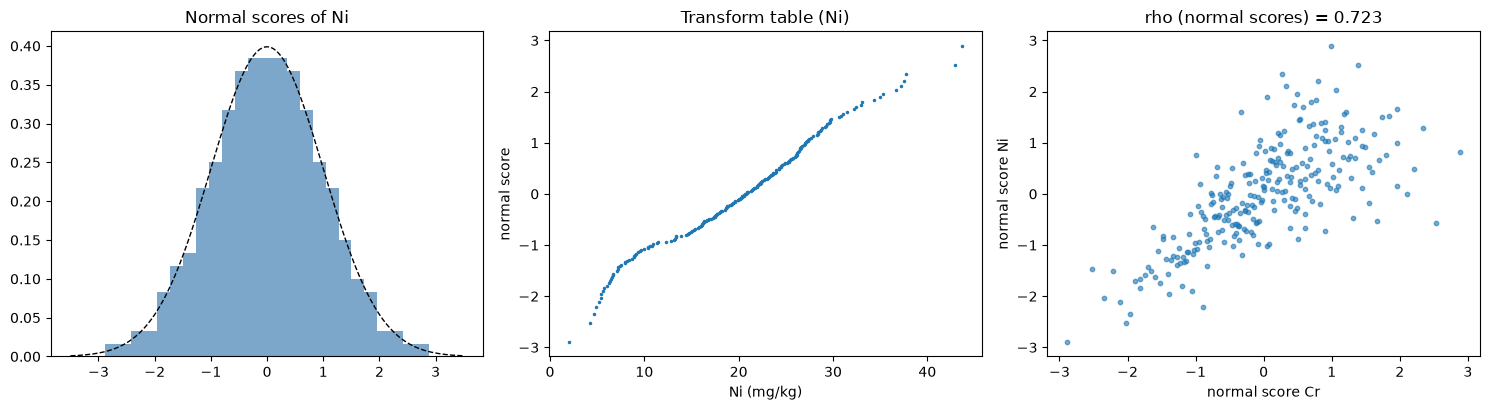

Ni scores: mean 0.000, variance 0.995
rho between Ni and Cr normal scores (259 sites) = 0.723
variance reduction far from data, 1 - rho^2      = 0.478


In [6]:
ni_ns, ni_vs, ni_nss = nscore_forward(df["Ni"].to_numpy(float), tails="linear")
cr_ns, _, _ = nscore_forward(df["Cr"].to_numpy(float), tails="linear")
rho_data = float(np.corrcoef(ni_ns, cr_ns)[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].hist(ni_ns, bins=25, density=True, alpha=0.7, color="steelblue")
hh = np.linspace(-3.5, 3.5, 200)
axes[0].plot(hh, norm.pdf(hh), "k--", lw=1)
axes[0].set_title("Normal scores of Ni")
axes[1].plot(ni_vs, ni_nss, ".", ms=3)
axes[1].set_xlabel("Ni (mg/kg)")
axes[1].set_ylabel("normal score")
axes[1].set_title("Transform table (Ni)")
axes[2].scatter(cr_ns, ni_ns, s=10, alpha=0.6)
axes[2].set_xlabel("normal score Cr")
axes[2].set_ylabel("normal score Ni")
axes[2].set_title(f"rho (normal scores) = {rho_data:.3f}")
plt.tight_layout()
plt.show()

print(f"Ni scores: mean {ni_ns.mean():.3f}, variance {ni_ns.var():.3f}")
print(f"rho between Ni and Cr normal scores (259 sites) = {rho_data:.3f}")
print(f"variance reduction far from data, 1 - rho^2      = {1 - rho_data**2:.3f}")

***
## Variogram of the Primary Normal Scores

The co-simulator needs one variogram: that of the primary **normal scores**. The experimental semivariogram of the Ni scores is computed in 0.125 km lags, and a spherical model in the GSLIB practical-range form is fitted by least squares with the sill fixed at 1 (the variance of normal scores). Chromium's variogram is fitted the same way. It is used by the hierarchical co-simulation in Section 12, which simulates Cr first.

vario_ni = [0.0, 0.216, 0.944, 0.944, 1.0, 'spherical']
vario_cr = [0.0, 0.294, 0.54, 0.54, 1.0, 'spherical']


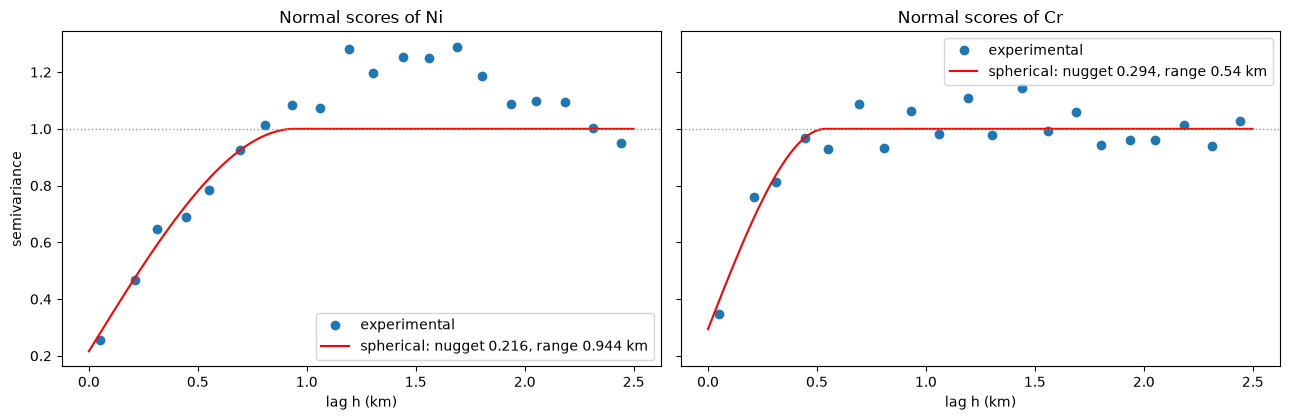

In [7]:
def experimental_variogram(xy, values, maxlag=2.5, n_lags=20):
    d = pdist(xy)
    g = 0.5 * pdist(values[:, None], "sqeuclidean")
    edges = np.linspace(0, maxlag, n_lags + 1)
    h, gam, npairs = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d > lo) & (d <= hi)
        h.append(d[m].mean()); gam.append(g[m].mean()); npairs.append(m.sum())
    return np.array(h), np.array(gam), np.array(npairs)


def spherical(h, nugget, a, sill=1.0):
    r = np.minimum(np.asarray(h) / a, 1.0)
    return nugget + (sill - nugget) * (1.5 * r - 0.5 * r ** 3)


def fit_spherical(h, gam, npairs):
    (nug, a), _ = curve_fit(lambda h, nug, a: spherical(h, nug, a), h, gam, p0=[0.2, 1.0],
                            bounds=([0.0, 0.1], [0.9, 5.0]), sigma=1 / np.sqrt(npairs))
    return float(nug), float(a)


h_ni, g_ni, n_ni = experimental_variogram(xy, ni_ns)
cr_ns_all, _, _ = nscore_forward(df["Cr"].to_numpy(float), tails="linear")
h_cr, g_cr, n_cr = experimental_variogram(xy, cr_ns_all)
nug_ni, a_ni = fit_spherical(h_ni, g_ni, n_ni)
nug_cr, a_cr = fit_spherical(h_cr, g_cr, n_cr)

vario_ni = [0.0, round(nug_ni, 3), round(a_ni, 3), round(a_ni, 3), 1.0, "spherical"]
vario_cr = [0.0, round(nug_cr, 3), round(a_cr, 3), round(a_cr, 3), 1.0, "spherical"]
print("vario_ni =", vario_ni)
print("vario_cr =", vario_cr)

hh = np.linspace(0, 2.5, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, (h, g, v, name) in zip(axes, [(h_ni, g_ni, vario_ni, "Ni"), (h_cr, g_cr, vario_cr, "Cr")]):
    ax.plot(h, g, "o", label="experimental")
    ax.plot(hh, spherical(hh, v[1], v[2]), "r-", label=f"spherical: nugget {v[1]}, range {v[2]} km")
    ax.axhline(1.0, color="0.6", ls=":", lw=1)
    ax.set_xlabel("lag h (km)")
    ax.set_title(f"Normal scores of {name}")
    ax.legend()
axes[0].set_ylabel("semivariance")
plt.tight_layout()
plt.show()

The fitted models are used unchanged for the rest of the notebook. `num_points = 16` informed neighbours and a 1.5 km search radius (about the Ni range) are used throughout.

In [8]:
NUM_POINTS = 16
RADIUS = 1.5  # km

***
## An Exhaustive Secondary: Chromium on the Grid

`GaussianCoSimulator` needs the secondary at **every** grid node. In Jura, chromium is measured at all 359 sites, so an exhaustive chromium map is built by ordinary kriging from all 359 samples, including the 100 validation sites where nickel is hidden. In other studies this map would come directly from a sensor: a geophysical survey, a satellite image, a DEM.

Chromium at the 100 validation sites is also needed (to co-simulate there in Section 10). It is predicted with the same kriging model; because it includes those sites' own Cr samples, the kriged value there is close to the measured Cr.

Cr kriged on the grid: min 13.9, mean 35.5, max 58.7 mg/kg
kriged vs measured Cr at the validation sites: corr = 0.994


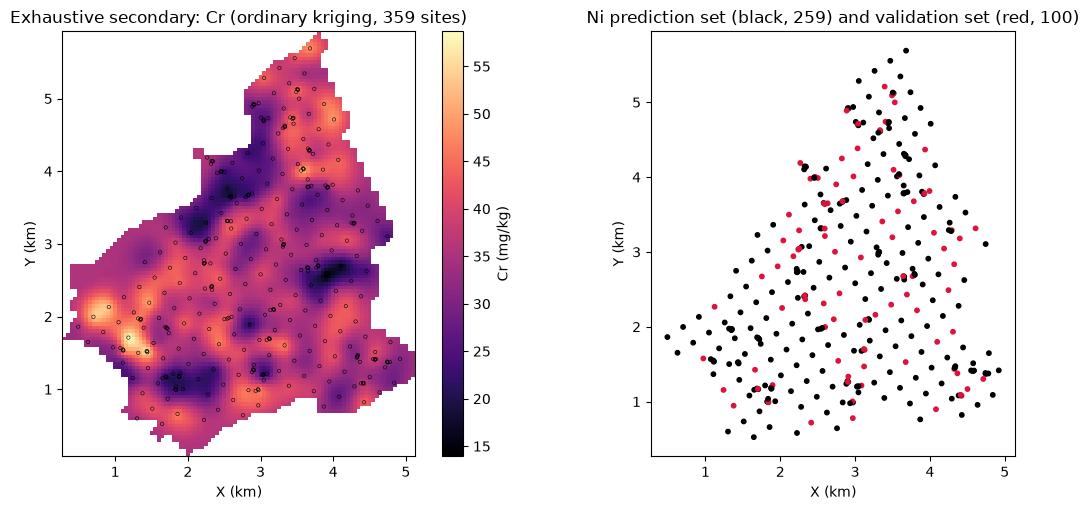

In [9]:
cr_all = df_all["Cr"].to_numpy(float)
vg_cr = Variogram(xy_all, cr_all, model="spherical", n_lags=15).fit()
ok_cr = OrdinaryKriging(vg_cr).fit(xy_all, cr_all)
cr_grid = np.asarray(ok_cr.predict(grid), dtype=float)
cr_test = np.asarray(ok_cr.predict(xy_test), dtype=float)
print(f"Cr kriged on the grid: min {cr_grid.min():.1f}, mean {cr_grid.mean():.1f}, max {cr_grid.max():.1f} mg/kg")
print(f"kriged vs measured Cr at the validation sites: corr = {np.corrcoef(cr_test, test.Cr)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
show_map(axes[0], cr_grid, "Exhaustive secondary: Cr (ordinary kriging, 359 sites)", cmap="magma", label="Cr (mg/kg)",
         points=xy_all)
axes[1].scatter(df_all["Xloc"], df_all["Yloc"], c=np.where(is_test, "crimson", "k"), s=10)
axes[1].set_aspect("equal")
axes[1].set_title("Ni prediction set (black, 259) and validation set (red, 100)")
axes[1].set_xlabel("X (km)")
axes[1].set_ylabel("Y (km)")
plt.tight_layout()
plt.show()

`fit` estimates $\rho$ from the Ni scores at the 259 sites and the **measured** Cr values there (`secondary_col="Cr"`), passed through the transform table of the exhaustive Cr map. It also computes the MM1 nugget diagnostic of Section 2.6.

In [10]:
cosim = GaussianCoSimulator(vario_ni, num_points=NUM_POINTS, radius=RADIUS, zmin=0.0, use_gpu=USE_GPU)
cosim.fit(grid, df, "Xloc", "Yloc", "Ni", secondary=cr_grid, secondary_col="Cr")
print(f"rho_               = {cosim.rho_:.3f}")
print(f"mm1_nugget_ratio_  = {cosim.mm1_nugget_ratio_:.3f}")
print(f"nodes              = {cosim.n_nodes_}")

rho_               = 0.702
mm1_nugget_ratio_  = -0.218
nodes              = 5957


The ratio is far below 1 (negative, in fact): the kriged Cr map is much **smoother** than Markov Model 1 says a secondary with this $\rho$ should be. That is expected for a kriged map. It is the case where the default **collocated** cokriging (`secondary_neighbors=1`) is preferred over multi-collocated cokriging (checked in Section 10), and it also raises a question about $\rho$ itself.

### Which $\rho$? The secondary as it exists at the nodes

$\rho$ enters the cokriging system as the correlation between the primary and **the secondary value used at the node**. At the 259 data sites that value was a Cr *measurement*. At the 5,957 grid nodes it is a Cr *kriging estimate*, which is smoother and less informative about Ni than a measurement. Using $\rho$ from measurements gives the secondary more weight than it deserves at unsampled nodes, and the realizations become too narrow.

The correlation that matches the nodes is the one between Ni and the Cr map *as it would be* at a site without its own Cr sample. Leave-one-out (LOO) kriging gives exactly that: krige Cr at each of the 259 sites from the other 358 Cr samples, and correlate the result with Ni.

rho from measured Cr at the data       : 0.702
rho from LOO-kriged Cr (map-like value) : 0.404


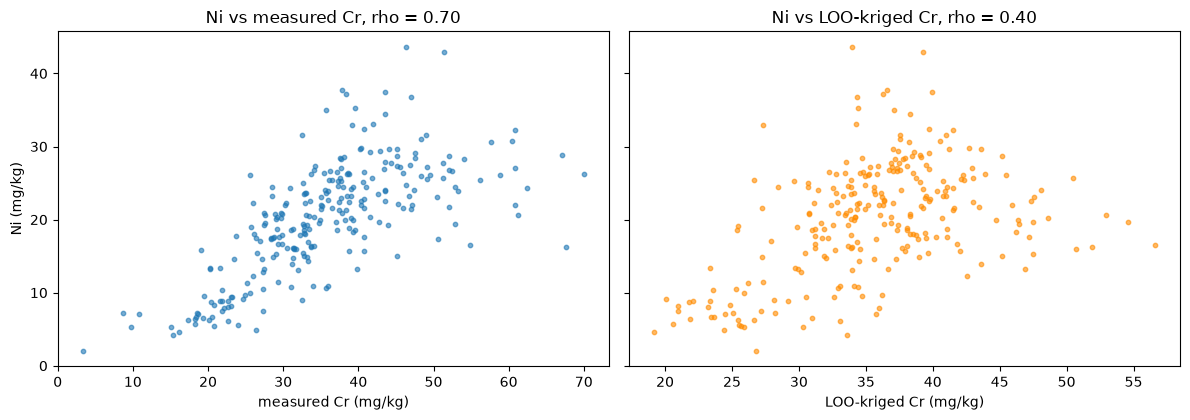

In [11]:
pred_rows = np.where(~is_test)[0]
cr_loo = np.empty(len(pred_rows))
for j, i in enumerate(pred_rows):
    keep = np.arange(len(df_all)) != i
    cr_loo[j] = float(np.asarray(OrdinaryKriging(vg_cr).fit(xy_all[keep], cr_all[keep]).predict(xy_all[i:i + 1]))[0])

rho_meas = cosim.rho_
cosim_map = GaussianCoSimulator(vario_ni, num_points=NUM_POINTS, radius=RADIUS, zmin=0.0, use_gpu=USE_GPU)
cosim_map.fit(grid, df.assign(Cr_loo=cr_loo), "Xloc", "Yloc", "Ni", secondary=cr_grid, secondary_col="Cr_loo")
rho_map = cosim_map.rho_
print(f"rho from measured Cr at the data       : {rho_meas:.3f}")
print(f"rho from LOO-kriged Cr (map-like value) : {rho_map:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
axes[0].scatter(df.Cr, df.Ni, s=10, alpha=0.6)
axes[0].set_xlabel("measured Cr (mg/kg)")
axes[0].set_title(f"Ni vs measured Cr, rho = {rho_meas:.2f}")
axes[1].scatter(cr_loo, df.Ni, s=10, alpha=0.6, c="darkorange")
axes[1].set_xlabel("LOO-kriged Cr (mg/kg)")
axes[1].set_title(f"Ni vs LOO-kriged Cr, rho = {rho_map:.2f}")
axes[0].set_ylabel("Ni (mg/kg)")
plt.tight_layout()
plt.show()

The map carries much less information about Ni than a Cr measurement does: $\rho$ falls from about 0.70 to about 0.40. From here on, `cosim` is the simulator fitted with the map-consistent $\rho$ (`cosim_map`). Section 10 compares both choices on the held-out sites, and Section 11 shows what each does to the realizations.

In [12]:
cosim_meas = cosim          # rho from measured Cr, kept for comparison
cosim = cosim_map           # rho from the LOO-kriged map: used below
print(f"cosim.rho_ = {cosim.rho_:.3f}")

cosim.rho_ = 0.404


***
## Baseline: Plain SGS with `sgsim_gpu`

`sgsim_gpu` is plain sequential Gaussian simulation (no secondary) on the same engine as `GaussianCoSimulator`, with `use_gpu=True` by default. It differs from `sgsim` in two ways: neighbours are the `num_points` nearest informed locations within `radius` (no octant search), and the default is **simple** kriging of the normal scores. It is the baseline the co-simulation is compared with.

First, the properties every conditional simulation must have: the data are reproduced exactly at their locations, the realizations differ away from the data, and the same seed gives the same realizations. The test grid is the 259 prediction sites plus 200 random grid nodes.

In [13]:
pick = np.random.default_rng(0).choice(len(grid), 200, replace=False)
small_grid = np.vstack([xy, grid[pick]])

sims_a = sgsim_gpu(small_grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS,
                   radius=RADIUS, nsim=8, seed=11, use_gpu=USE_GPU)
sims_b = sgsim_gpu(small_grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS,
                   radius=RADIUS, nsim=8, seed=11, use_gpu=USE_GPU)
sims_c = sgsim_gpu(small_grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS,
                   radius=RADIUS, nsim=8, seed=12, use_gpu=USE_GPU)

err = np.abs(sims_a[:, :len(df)] - df["Ni"].to_numpy()).max()
record("sgsim_gpu: exact conditioning", "PASS" if err < 1e-6 else "FAIL", f"max |sim - data| = {err:.1e}")
spread = sims_a[:, len(df):].std(axis=0).mean()
record("sgsim_gpu: realizations vary away from data", "PASS" if spread > 0.5 else "FAIL",
       f"mean std across realizations = {spread:.2f} mg/kg")
record("sgsim_gpu: same seed -> identical", "PASS" if np.array_equal(sims_a, sims_b) else "FAIL")
record("sgsim_gpu: different seed -> different", "PASS" if not np.allclose(sims_a, sims_c) else "FAIL")

sims_cpu = sgsim_gpu(small_grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS,
                     radius=RADIUS, nsim=8, seed=11, use_gpu=False)
diff = np.abs(sims_cpu - sims_a).max()
record("sgsim_gpu: GPU = CPU for the same seed", "PASS" if diff < 1e-6 else "FAIL",
       f"max |GPU - CPU| = {diff:.1e} mg/kg" + ("" if USE_GPU else " (no GPU: both ran on CPU)"))

✅ [PASS] sgsim_gpu: exact conditioning  max |sim - data| = 0.0e+00
✅ [PASS] sgsim_gpu: realizations vary away from data  mean std across realizations = 4.47 mg/kg
✅ [PASS] sgsim_gpu: same seed -> identical  
✅ [PASS] sgsim_gpu: different seed -> different  
✅ [PASS] sgsim_gpu: GPU = CPU for the same seed  max |GPU - CPU| = 6.2e-14 mg/kg


### Simple vs ordinary kriging

`kriging_type="ordinary"` re-estimates the local mean at every node. Both versions are run on the full grid with 100 realizations. Because the OK variance exceeds the SK variance, ordinary kriging can inflate the variance of the realizations; with this dense data set the difference is small.

In [14]:
N_SIM = 100
t0 = time.perf_counter()
sgs_sk = sgsim_gpu(grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS, radius=RADIUS,
                   nsim=N_SIM, seed=2024, zmin=0.0, use_gpu=USE_GPU)
t_sk = time.perf_counter() - t0
sgs_ok = sgsim_gpu(grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS, radius=RADIUS,
                   kriging_type="ordinary", nsim=N_SIM, seed=2024, zmin=0.0, use_gpu=USE_GPU)
print(f"{N_SIM} realizations x {len(grid)} nodes: {t_sk:.1f} s ({'GPU' if USE_GPU else 'CPU'})")
print(f"data       : mean {df.Ni.mean():6.2f}  sd {df.Ni.std():5.2f}")
print(f"SGS simple : mean {sgs_sk.mean():6.2f}  sd {sgs_sk.std(axis=1).mean():5.2f}   (sd = mean within-realization sd)")
print(f"SGS ordin. : mean {sgs_ok.mean():6.2f}  sd {sgs_ok.std(axis=1).mean():5.2f}")

100 realizations x 5957 nodes: 2.9 s (GPU)
data       : mean  20.14  sd  7.75
SGS simple : mean  20.88  sd  7.29   (sd = mean within-realization sd)
SGS ordin. : mean  20.96  sd  7.39


***
## Co-Simulation with `GaussianCoSimulator` and `sgcosim`

The fitted `cosim` object from Section 7 (map-consistent $\rho$) simulates 100 realizations of Ni on the full grid, using the kriged Cr map at every node. `sgcosim` is the one-call equivalent, here with `rho=rho_map` passed explicitly; both give identical realizations for the same seed.

In [15]:
t0 = time.perf_counter()
cos = cosim.simulate(nsim=N_SIM, seed=2024)
t_cos = time.perf_counter() - t0
print(f"GaussianCoSimulator: {cos.shape[0]} realizations x {cos.shape[1]} nodes in {t_cos:.1f} s")

cos_fn = sgcosim(grid, df, "Xloc", "Yloc", "Ni", vario_ni, secondary=cr_grid, rho=rho_map,
                 num_points=NUM_POINTS, radius=RADIUS, nsim=N_SIM, seed=2024, zmin=0.0)
record("sgcosim == GaussianCoSimulator(...).simulate (same seed)",
       "PASS" if np.allclose(cos, cos_fn, atol=1e-6) else "FAIL",
       f"max diff = {np.abs(cos - cos_fn).max():.1e} (sgcosim on CPU, class on {'GPU' if USE_GPU else 'CPU'})")

# exact conditioning: simulate on the data locations too
cond_check = GaussianCoSimulator(vario_ni, rho=rho_map, num_points=NUM_POINTS, radius=RADIUS).fit(
    small_grid, df, "Xloc", "Yloc", "Ni", secondary=np.r_[df.Cr.to_numpy(float), cr_grid[pick]]).simulate(
    nsim=5, seed=3)
err = np.abs(cond_check[:, :len(df)] - df["Ni"].to_numpy()).max()
record("co-simulation: exact conditioning", "PASS" if err < 1e-6 else "FAIL", f"max |sim - data| = {err:.1e}")

GaussianCoSimulator: 100 realizations x 5957 nodes in 3.4 s


✅ [PASS] sgcosim == GaussianCoSimulator(...).simulate (same seed)  max diff = 2.5e-13 (sgcosim on CPU, class on GPU)
✅ [PASS] co-simulation: exact conditioning  max |sim - data| = 0.0e+00


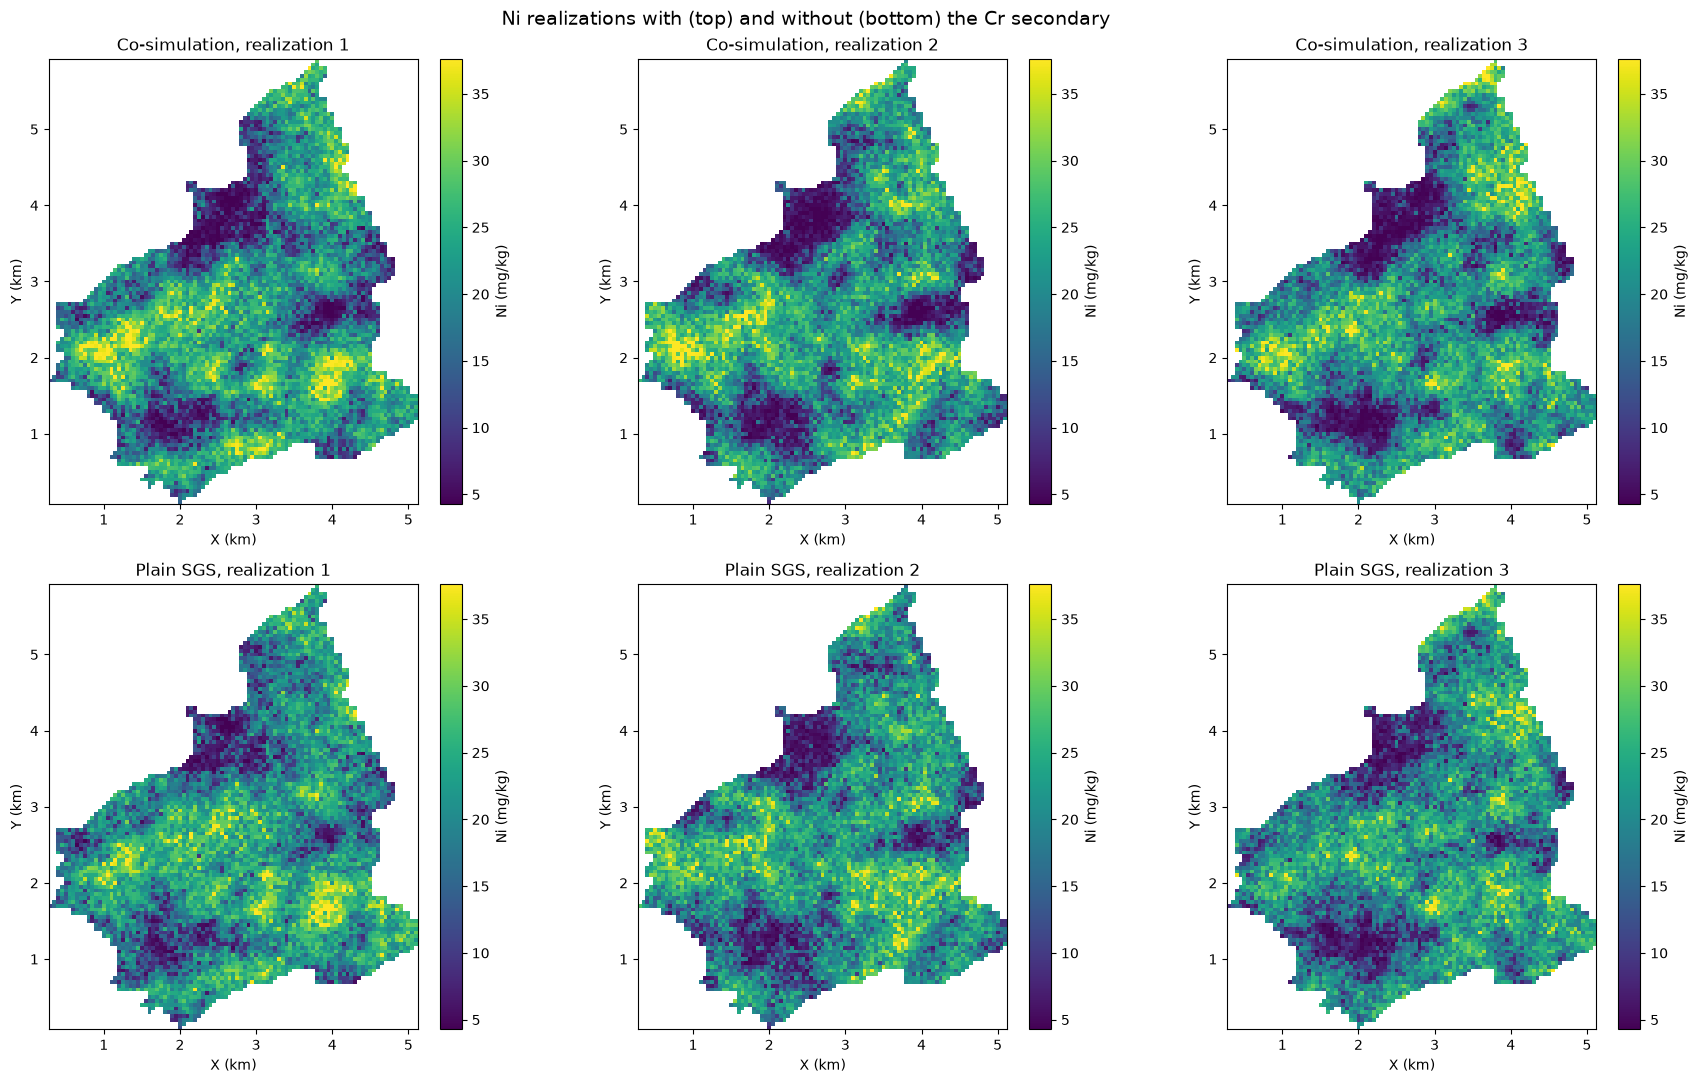

In [16]:
vmin, vmax = np.percentile(np.r_[cos.ravel(), sgs_sk.ravel()], [1, 99])
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, r in zip(axes[0], [0, 1, 2]):
    show_map(ax, cos[r], f"Co-simulation, realization {r + 1}", vmin=vmin, vmax=vmax)
for ax, r in zip(axes[1], [0, 1, 2]):
    show_map(ax, sgs_sk[r], f"Plain SGS, realization {r + 1}", vmin=vmin, vmax=vmax)
fig.suptitle("Ni realizations with (top) and without (bottom) the Cr secondary", fontsize=14)
plt.tight_layout()
plt.show()

The co-simulated realizations share the large-scale pattern of the Cr map: they differ from each other mainly at short range. The plain SGS realizations are free to differ wherever the Ni data are sparse. The E-type (mean of the realizations) and the standard deviation make this explicit.

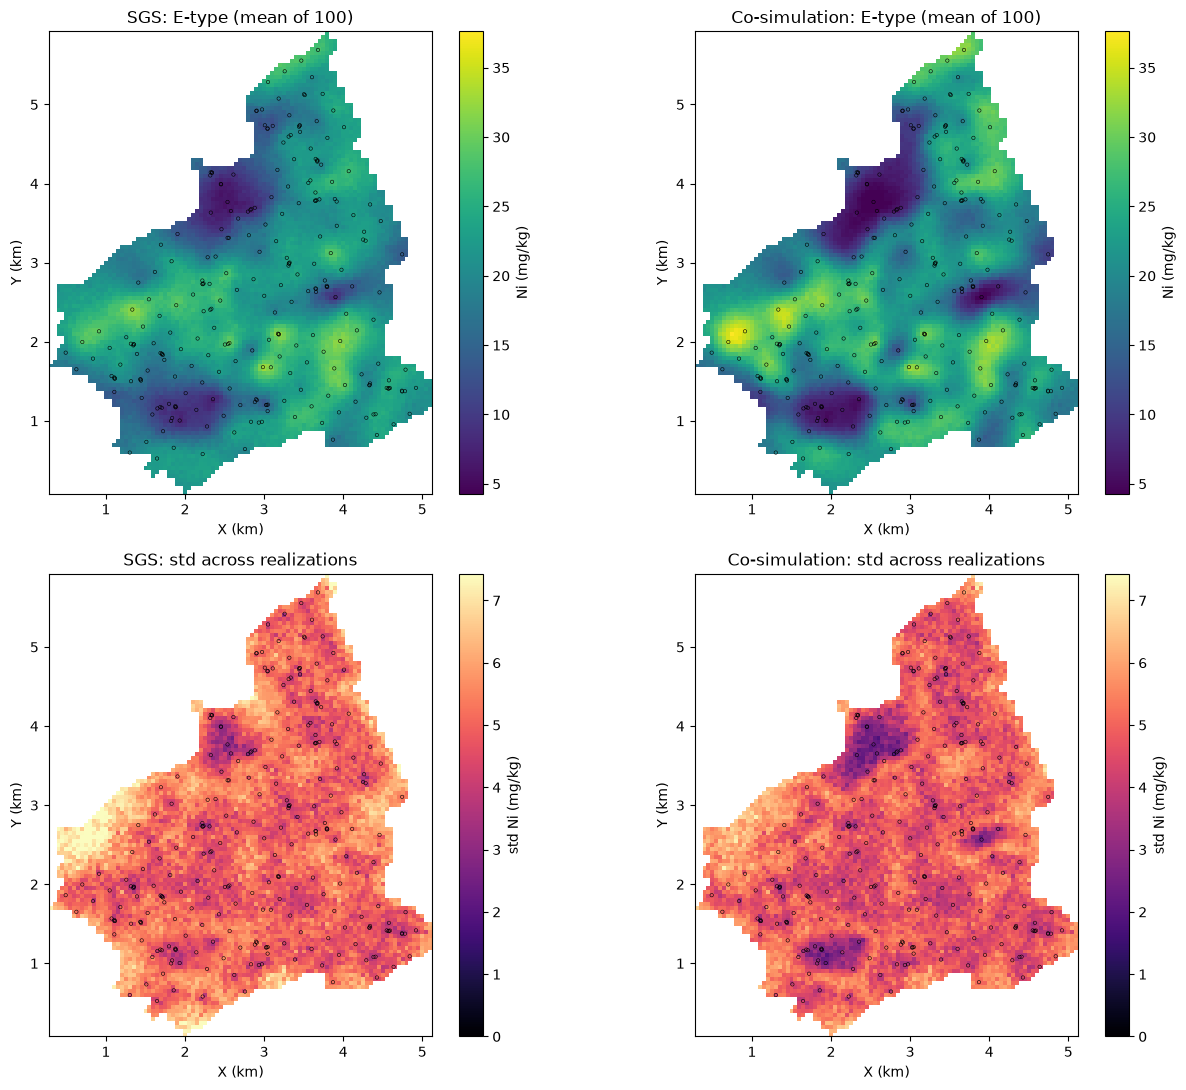

mean conditional std:  SGS 5.21 mg/kg   co-simulation 4.81 mg/kg   (ratio 0.92; sqrt(1 - rho^2) = 0.91)


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
show_map(axes[0, 0], sgs_sk.mean(0), "SGS: E-type (mean of 100)", vmin=vmin, vmax=vmax, points=xy)
show_map(axes[0, 1], cos.mean(0), "Co-simulation: E-type (mean of 100)", vmin=vmin, vmax=vmax, points=xy)
smax = np.percentile(sgs_sk.std(0), 99)
show_map(axes[1, 0], sgs_sk.std(0), "SGS: std across realizations", cmap="magma", vmin=0, vmax=smax,
         label="std Ni (mg/kg)", points=xy)
show_map(axes[1, 1], cos.std(0), "Co-simulation: std across realizations", cmap="magma", vmin=0, vmax=smax,
         label="std Ni (mg/kg)", points=xy)
plt.tight_layout()
plt.show()
print(f"mean conditional std:  SGS {sgs_sk.std(0).mean():.2f} mg/kg   co-simulation {cos.std(0).mean():.2f} mg/kg   "
      f"(ratio {cos.std(0).mean() / sgs_sk.std(0).mean():.2f}; sqrt(1 - rho^2) = {np.sqrt(1 - cosim.rho_**2):.2f})")

### How the correlation $\rho$ shapes the realizations

$\rho$ can be passed explicitly instead of being estimated. With the same seed, $\rho = 0$ gives plain SGS on this engine, and as $\rho \to 1$ the realization approaches a rescaled copy of the secondary. The panels below use one seed and four values of $\rho$: 0, the map-consistent value, the measurement value, and 0.95. Each title also gives the rank correlation between the realization and the Cr map.

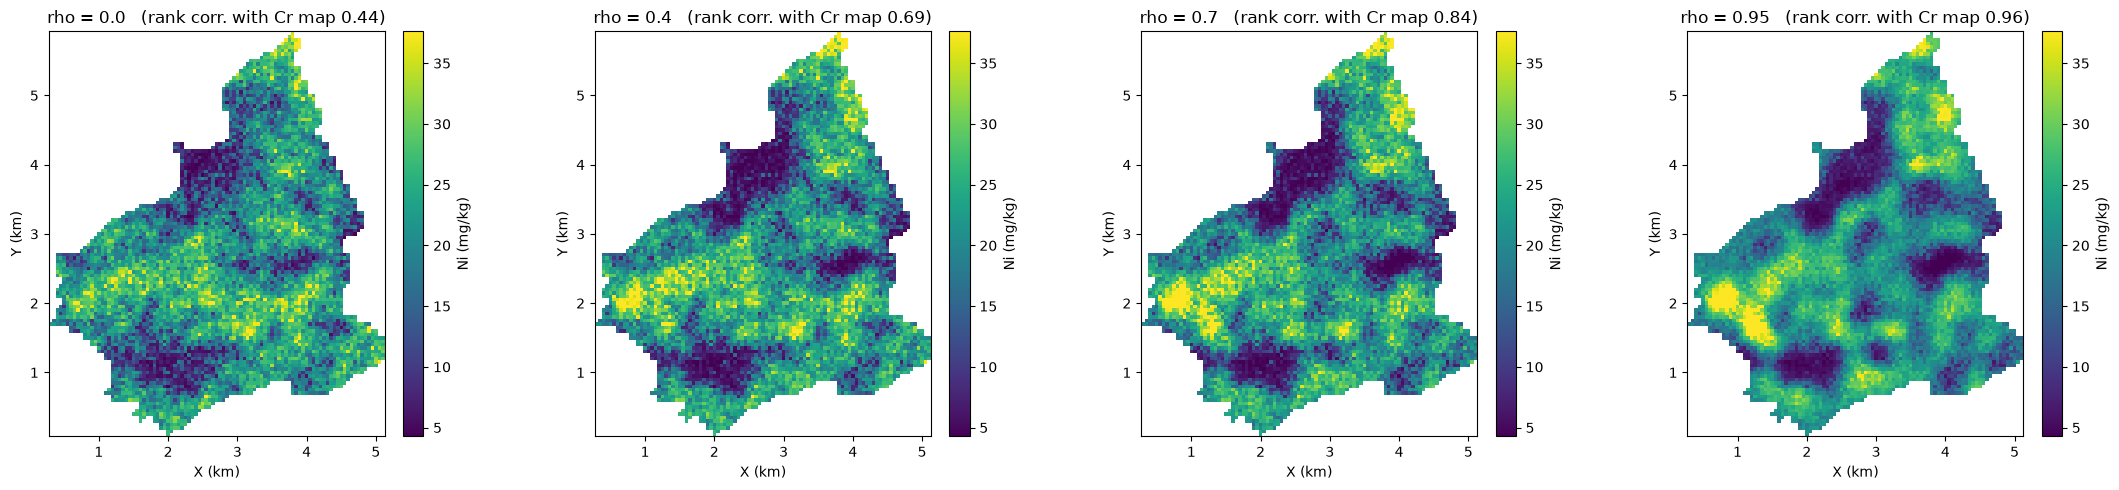

✅ [PASS] rho = 0 reduces to plain SGS (same seed)  max diff = 0.0e+00


In [18]:
rhos = [0.0, round(rho_map, 2), round(rho_meas, 2), 0.95]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, rho in zip(axes, rhos):
    one = sgcosim(grid, df, "Xloc", "Yloc", "Ni", vario_ni, secondary=cr_grid, rho=rho,
                  num_points=NUM_POINTS, radius=RADIUS, nsim=1, seed=7, zmin=0.0, use_gpu=USE_GPU)[0]
    r_sec = spearmanr(one, cr_grid).correlation
    show_map(ax, one, f"rho = {rho}   (rank corr. with Cr map {r_sec:.2f})", vmin=vmin, vmax=vmax)
plt.tight_layout()
plt.show()

sgs_same = sgsim_gpu(grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS, radius=RADIUS,
                     nsim=1, seed=7, zmin=0.0, use_gpu=USE_GPU)[0]
rho0 = sgcosim(grid, df, "Xloc", "Yloc", "Ni", vario_ni, secondary=cr_grid, rho=0.0,
               num_points=NUM_POINTS, radius=RADIUS, nsim=1, seed=7, zmin=0.0, use_gpu=USE_GPU)[0]
record("rho = 0 reduces to plain SGS (same seed)", "PASS" if np.allclose(sgs_same, rho0) else "FAIL",
       f"max diff = {np.abs(sgs_same - rho0).max():.1e}")

***
## Validation at 100 Held-Out Sites

The 100 validation sites were never used for nickel. The three simulators below draw 500 realizations at those sites, conditioned on the 259 Ni data. For co-simulation, the secondary at each site is the kriged Cr there.

* **SGS:** `sgsim_gpu`, no secondary.
* **Collocated, $\rho$ from measured Cr** (`rho_meas`, the default estimate with `secondary_col="Cr"`).
* **Collocated, $\rho$ from the LOO map** (`rho_map`).
* **Multi-collocated** (`secondary_neighbors=5`, `rho_map`; CPU only, 50 realizations).

Each simulator is scored on the true Ni values:

| Metric | Meaning | Better |
|---|---|---|
| RMSE, MAE of the E-type | accuracy of the mean of the realizations | lower |
| correlation (E-type, truth) | how well the spatial pattern is predicted | higher |
| coverage of the 80% interval | fraction of true values between the 10th and 90th percentile of the realizations | close to 0.80 |
| width of the 80% interval | sharpness of the local distributions | lower, *if* coverage holds |
| CRPS | continuous ranked probability score of the whole local distribution | lower |

The **accuracy plot** (Deutsch, 1997) extends the coverage check to every probability interval $p$: the fraction of true values inside the symmetric $p$-interval should lie on or slightly above the 1:1 line.

The secondary at the validation sites is kriged from samples that include those very sites. That is the undersampled design (Cr is measured there), not leakage of Ni: nickel at the validation sites is never used, and `rho_` is estimated from the 259 prediction sites only.

In [19]:
N_VAL = 500
truth = test["Ni"].to_numpy(float)
sec_val = np.r_[cr_grid, cr_test]      # transform table from the full map + the validation sites
val_grid = np.vstack([grid, xy_test])
val_idx = slice(len(grid), None)


def crps_ensemble(ens, obs):
    # CRPS = E|X - y| - 0.5 E|X - X'|, per site
    ens = np.sort(ens, axis=0)
    m = ens.shape[0]
    t1 = np.abs(ens - obs).mean(0)
    w = (2 * np.arange(1, m + 1) - m - 1) / (m * m)
    t2 = (w[:, None] * ens).sum(0)
    return t1 - t2


def score(name, ens):
    et = ens.mean(0)
    lo, hi = np.percentile(ens, [10, 90], axis=0)
    return {"method": name, "RMSE": np.sqrt(np.mean((et - truth) ** 2)), "MAE": np.mean(np.abs(et - truth)),
            "corr": np.corrcoef(et, truth)[0, 1], "cover80": np.mean((truth >= lo) & (truth <= hi)),
            "width80": np.mean(hi - lo), "CRPS": crps_ensemble(ens, truth).mean()}


# simulate on grid + validation sites so the validation values come from realizations of the whole field
t0 = time.perf_counter()
ens_sgs = sgsim_gpu(val_grid, df, "Xloc", "Yloc", "Ni", vario_ni, num_points=NUM_POINTS, radius=RADIUS,
                    nsim=N_VAL, seed=1, zmin=0.0, use_gpu=USE_GPU)[:, val_idx]
ens_meas = sgcosim(val_grid, df, "Xloc", "Yloc", "Ni", vario_ni, secondary=sec_val, rho=rho_meas,
                   num_points=NUM_POINTS, radius=RADIUS, nsim=N_VAL, seed=1, zmin=0.0,
                   use_gpu=USE_GPU)[:, val_idx]
ens_col = sgcosim(val_grid, df, "Xloc", "Yloc", "Ni", vario_ni, secondary=sec_val, rho=rho_map,
                  num_points=NUM_POINTS, radius=RADIUS, nsim=N_VAL, seed=1, zmin=0.0,
                  use_gpu=USE_GPU)[:, val_idx]
multi = GaussianCoSimulator(vario_ni, rho=rho_map, num_points=NUM_POINTS, radius=RADIUS, zmin=0.0,
                            secondary_neighbors=5)
ens_mul = multi.fit(val_grid, df, "Xloc", "Yloc", "Ni", secondary=sec_val).simulate(
    nsim=50, seed=1)[:, val_idx]   # CPU only (GPU supports the collocated secondary); 50 realizations
print(f"simulated in {time.perf_counter() - t0:.0f} s")

table = pd.DataFrame([score("SGS (no secondary)", ens_sgs),
                      score(f"collocated, rho_meas = {rho_meas:.2f}", ens_meas),
                      score(f"collocated, rho_map = {rho_map:.2f}", ens_col),
                      score("multi-collocated m=5 (50 real.)", ens_mul)]).set_index("method")
table.round(3)

simulated in 34 s


,RMSE,MAE,corr,cover80,width80,CRPS
method,,,,,,
SGS (no secondary),5.666,4.224,0.779,0.81,12.552,3.053
"collocated, rho_meas = 0.70",5.367,4.141,0.827,0.64,9.437,3.037
"collocated, rho_map = 0.40",4.906,3.492,0.843,0.85,11.306,2.607
multi-collocated m=5 (50 real.),5.536,4.045,0.819,0.69,10.253,3.060


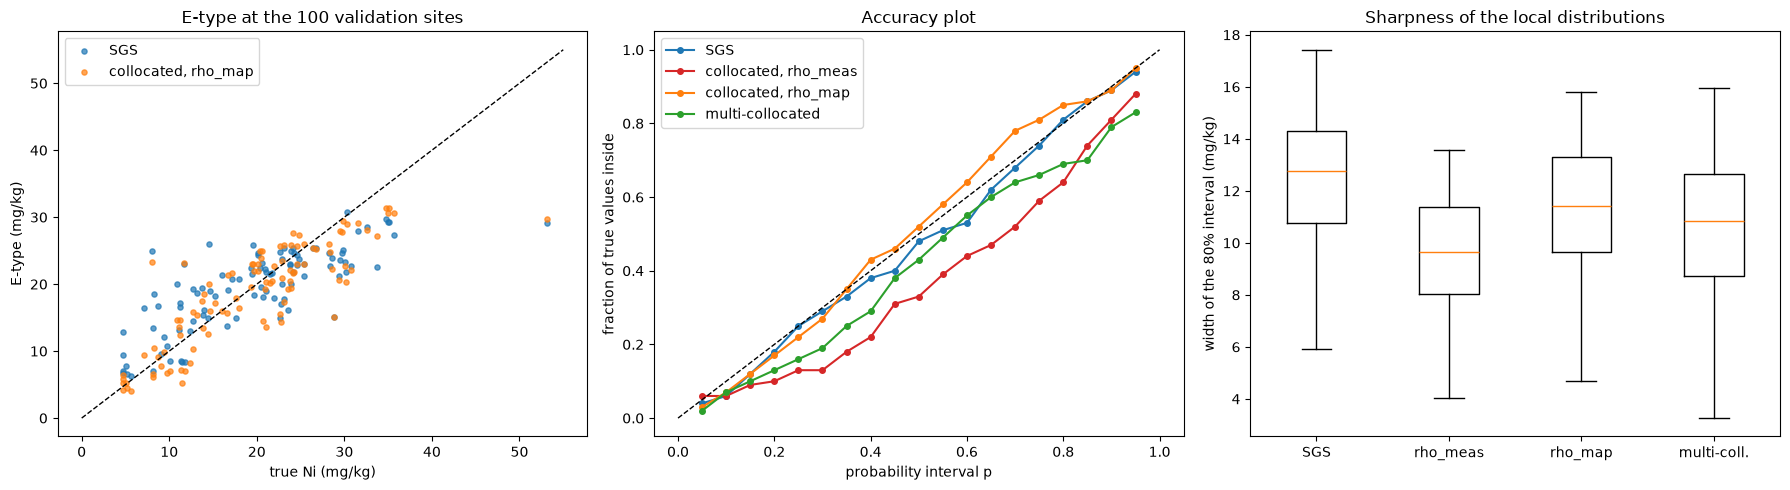

✅ [PASS] co-simulation (rho_map) lowers E-type RMSE vs SGS  5.67 -> 4.91 mg/kg
✅ [PASS] co-simulation (rho_map) lowers CRPS vs SGS  3.05 -> 2.61
✅ [PASS] co-simulation (rho_map) 80% interval coverage in [0.70, 0.90]  coverage = 0.85, width = 11.3 mg/kg (SGS 12.6)


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ens, name, c in [(ens_sgs, "SGS", "tab:blue"), (ens_col, "collocated, rho_map", "tab:orange")]:
    axes[0].scatter(truth, ens.mean(0), s=14, alpha=0.7, c=c, label=name)
axes[0].plot([0, 55], [0, 55], "k--", lw=1)
axes[0].set_xlabel("true Ni (mg/kg)")
axes[0].set_ylabel("E-type (mg/kg)")
axes[0].set_title("E-type at the 100 validation sites")
axes[0].legend()

ps = np.linspace(0.05, 0.95, 19)
for ens, name, c in [(ens_sgs, "SGS", "tab:blue"), (ens_meas, "collocated, rho_meas", "tab:red"),
                     (ens_col, "collocated, rho_map", "tab:orange"), (ens_mul, "multi-collocated", "tab:green")]:
    frac = [np.mean((truth >= np.percentile(ens, 50 - 50 * p, axis=0)) &
                    (truth <= np.percentile(ens, 50 + 50 * p, axis=0))) for p in ps]
    axes[1].plot(ps, frac, "o-", ms=4, c=c, label=name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("probability interval p")
axes[1].set_ylabel("fraction of true values inside")
axes[1].set_title("Accuracy plot")
axes[1].legend()

axes[2].boxplot([np.diff(np.percentile(e, [10, 90], axis=0), axis=0).ravel()
                 for e in (ens_sgs, ens_meas, ens_col, ens_mul)])
axes[2].set_xticks([1, 2, 3, 4], ["SGS", "rho_meas", "rho_map", "multi-coll."])
axes[2].set_ylabel("width of the 80% interval (mg/kg)")
axes[2].set_title("Sharpness of the local distributions")
plt.tight_layout()
plt.show()

t = table
sgs_row, col_row = t.iloc[0], t.iloc[2]
record("co-simulation (rho_map) lowers E-type RMSE vs SGS", "PASS" if col_row.RMSE < sgs_row.RMSE else "FAIL",
       f"{sgs_row.RMSE:.2f} -> {col_row.RMSE:.2f} mg/kg")
record("co-simulation (rho_map) lowers CRPS vs SGS", "PASS" if col_row.CRPS < sgs_row.CRPS else "FAIL",
       f"{sgs_row.CRPS:.2f} -> {col_row.CRPS:.2f}")
record("co-simulation (rho_map) 80% interval coverage in [0.70, 0.90]",
       "PASS" if 0.70 <= col_row.cover80 <= 0.90 else "FAIL",
       f"coverage = {col_row.cover80:.2f}, width = {col_row.width80:.1f} mg/kg (SGS {sgs_row.width80:.1f})")

Reading the table and the plots:

* **The choice of $\rho$ decides whether co-simulation helps.** With the map-consistent $\rho = 0.40$, co-simulation beats SGS on every measure: E-type RMSE 5.67 → 4.91 mg/kg, MAE 4.22 → 3.49, correlation with the truth 0.78 → 0.84, CRPS 3.05 → 2.61. Its 80% intervals are about 10% narrower (11.3 vs 12.6 mg/kg) and still cover 85% of the true values. Its accuracy-plot curve sits on or just above the 1:1 line: the local distributions are accurate and slightly conservative.
* **With $\rho = 0.70$ from measurements, the realizations are over-confident.** The intervals are the narrowest (9.4 mg/kg), but they cover only 64% of the true values, and the accuracy curve falls below the 1:1 line at every $p$. The secondary gets more weight than a kriged map deserves. CRPS, which rewards sharpness *and* calibration, is then no better than SGS.
* **Multi-collocated cokriging does not help here.** As the `mm1_nugget_ratio_` predicted for a smooth secondary, using the map at 5 nodes per step over-uses it: lower coverage (0.69) and higher error than collocated cokriging with the same $\rho$.
* **Plain SGS is well calibrated** (coverage 0.81) but wider and less accurate: it knows nothing about Cr.

### Scanning the input $\rho$

The same check over a range of input $\rho$ shows the trade-off directly. For each value, 300 realizations are scored on the validation sites, and 30 realizations in normal-score units give the realized correlation between the simulated Ni and the Cr map on the grid.

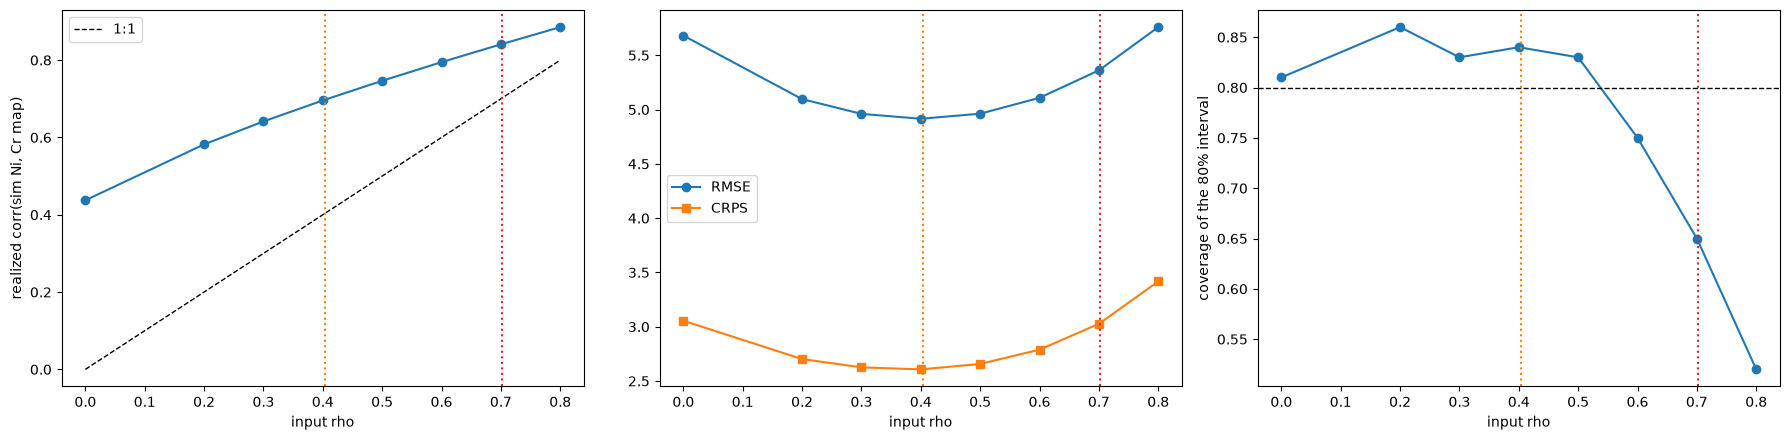

,realized corr. with map,RMSE,MAE,corr,cover80,width80,CRPS
rho_in,,,,,,,
0.0,0.437,5.682,4.234,0.778,0.81,12.500,3.055
0.2,0.582,5.096,3.659,0.826,0.86,12.065,2.702
0.3,0.641,4.961,3.531,0.837,0.83,11.747,2.626
0.4,0.696,4.916,3.494,0.843,0.84,11.364,2.607
0.5,0.747,4.962,3.562,0.843,0.83,10.868,2.657
0.6,0.795,5.108,3.780,0.838,0.75,10.246,2.789
0.7,0.841,5.361,4.132,0.827,0.65,9.469,3.027
0.8,0.885,5.760,4.606,0.809,0.52,8.410,3.417


In [21]:
scan = []
for rho_in in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    sim = GaussianCoSimulator(vario_ni, rho=rho_in, num_points=NUM_POINTS, radius=RADIUS, zmin=0.0,
                              use_gpu=USE_GPU).fit(val_grid, df, "Xloc", "Yloc", "Ni", secondary=sec_val)
    ens = sim.simulate(nsim=300, seed=1)[:, val_idx]
    ns = sim.simulate(nsim=30, seed=2, back_transform=False)[:, :len(grid)]
    realized = np.mean([np.corrcoef(ns[r], sim.secondary_scores_[:len(grid)])[0, 1] for r in range(30)])
    scan.append({"rho_in": rho_in, "realized corr. with map": realized, **score("", ens)})
scan = pd.DataFrame(scan).drop(columns="method").set_index("rho_in")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(scan.index, scan["realized corr. with map"], "o-")
axes[0].plot([0, 0.8], [0, 0.8], "k--", lw=1, label="1:1")
axes[0].set_xlabel("input rho")
axes[0].set_ylabel("realized corr(sim Ni, Cr map)")
axes[0].legend()
axes[1].plot(scan.index, scan["RMSE"], "o-", label="RMSE")
axes[1].plot(scan.index, scan["CRPS"], "s-", label="CRPS")
axes[1].set_xlabel("input rho")
axes[1].legend()
axes[2].plot(scan.index, scan["cover80"], "o-")
axes[2].axhline(0.8, color="k", ls="--", lw=1)
axes[2].set_xlabel("input rho")
axes[2].set_ylabel("coverage of the 80% interval")
for ax in axes:
    ax.axvline(rho_map, color="tab:orange", ls=":", lw=1.5)
    ax.axvline(rho_meas, color="tab:red", ls=":", lw=1.5)
plt.tight_layout()
plt.show()
scan.round(3)

The scan confirms the choice:

* **Accuracy** (RMSE, CRPS) is best for input $\rho$ between about 0.3 and 0.5, and the LOO estimate $\rho_{map} = 0.40$ (orange line) falls at the minimum. Above 0.5 the error rises again, and at the measurement value (red line) it is back near SGS.
* **Calibration:** coverage stays near or above 0.80 up to $\rho \approx 0.5$, then falls quickly (0.65 at 0.7, 0.52 at 0.8). The intervals keep narrowing as $\rho$ grows, but past 0.5 they narrow for the wrong reason.
* **Realized correlation is always higher than the input $\rho$** with this smooth secondary. Even at $\rho = 0$ the realizations correlate 0.44 with the Cr map, because the Ni data they honour are themselves correlated with Cr. At $\rho_{map} = 0.40$ the realized correlation with the map is about 0.70, the Ni-Cr correlation of the measurements.

When held-out data are not available, the LOO correlation between the primary and the cross-validated secondary map is a cheap and effective way to set $\rho$.

***
## Reproduction of Histogram, Variogram and Correlation

Co-simulation should reproduce the **histogram** of Ni and the **variogram** of the Ni normal scores, and it should carry the secondary's pattern into the realizations through $\rho$. The realizations are drawn again with `back_transform=False`, which returns them in normal-score units, so the variogram and correlation can be compared with the model directly.

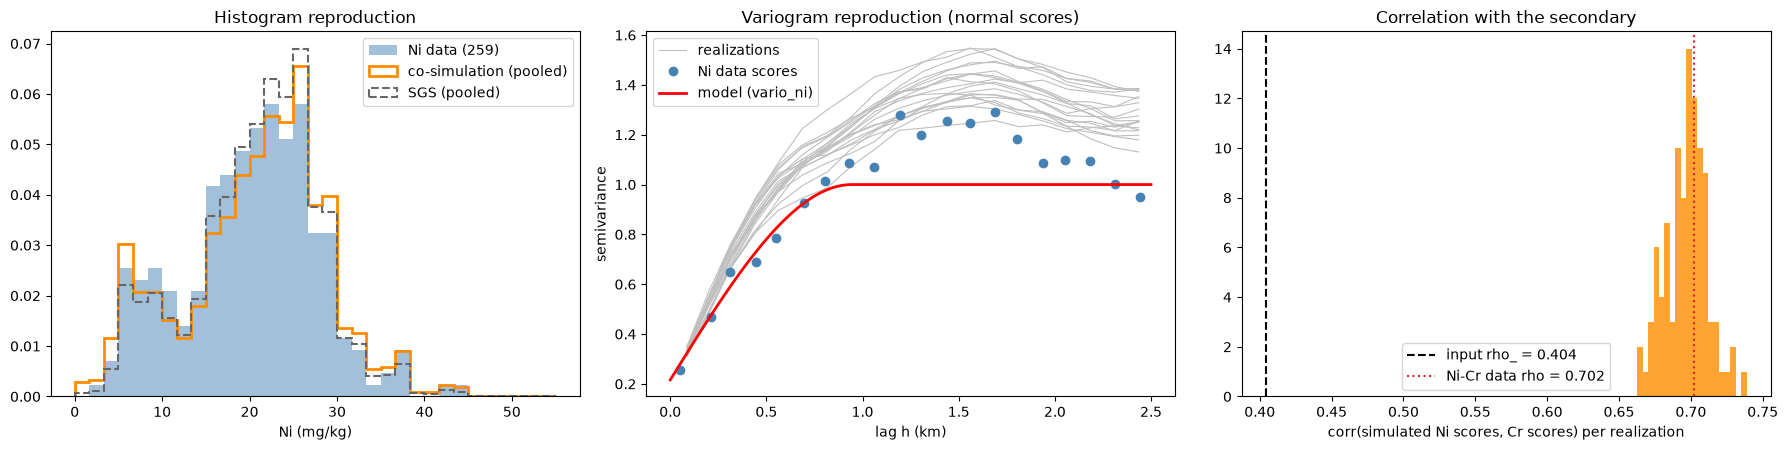

Ni data      : mean 20.14  sd 7.75  q10 8.62  q90 28.75
co-simulation: mean 20.69  sd 8.21  q10 7.47  q90 29.66
realized correlation with the Cr map: mean 0.697 (sd 0.014); input rho_ 0.404; Ni-Cr correlation of the data 0.702
✅ [PASS] co-simulation histogram reproduction (mean within 10%)  data 20.14, simulated 20.69


In [22]:
cos_ns = cosim.simulate(nsim=N_SIM, seed=2024, back_transform=False)

# histogram (original units)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
bins = np.linspace(0, 55, 34)
axes[0].hist(df["Ni"], bins=bins, density=True, alpha=0.5, color="steelblue", label="Ni data (259)")
axes[0].hist(cos.ravel(), bins=bins, density=True, histtype="step", lw=2, color="darkorange",
             label="co-simulation (pooled)")
axes[0].hist(sgs_sk.ravel(), bins=bins, density=True, histtype="step", lw=1.5, color="0.4", ls="--",
             label="SGS (pooled)")
axes[0].set_xlabel("Ni (mg/kg)")
axes[0].set_title("Histogram reproduction")
axes[0].legend()

# variogram of normal-score realizations on a random subset of nodes
sub = np.random.default_rng(5).choice(len(grid), 1500, replace=False)
for r in range(20):
    h_r, g_r, _ = experimental_variogram(grid[sub], cos_ns[r, sub])
    axes[1].plot(h_r, g_r, color="0.75", lw=0.8, label="realizations" if r == 0 else None)
axes[1].plot(h_ni, g_ni, "o", color="steelblue", label="Ni data scores")
axes[1].plot(hh, spherical(hh, vario_ni[1], vario_ni[2]), "r-", lw=2, label="model (vario_ni)")
axes[1].set_xlabel("lag h (km)")
axes[1].set_ylabel("semivariance")
axes[1].set_title("Variogram reproduction (normal scores)")
axes[1].legend()

# correlation with the secondary scores at the grid nodes
rho_real = np.array([np.corrcoef(cos_ns[r], cosim.secondary_scores_)[0, 1] for r in range(N_SIM)])
axes[2].hist(rho_real, bins=20, color="darkorange", alpha=0.8)
axes[2].axvline(cosim.rho_, color="k", ls="--", label=f"input rho_ = {cosim.rho_:.3f}")
axes[2].axvline(rho_meas, color="tab:red", ls=":", label=f"Ni-Cr data rho = {rho_meas:.3f}")
axes[2].set_xlabel("corr(simulated Ni scores, Cr scores) per realization")
axes[2].set_title("Correlation with the secondary")
axes[2].legend()
plt.tight_layout()
plt.show()

print(f"Ni data      : mean {df.Ni.mean():.2f}  sd {df.Ni.std():.2f}  q10 {df.Ni.quantile(.1):.2f}  q90 {df.Ni.quantile(.9):.2f}")
print(f"co-simulation: mean {cos.mean():.2f}  sd {cos.std(axis=1).mean():.2f}  q10 {np.quantile(cos, .1):.2f}  q90 {np.quantile(cos, .9):.2f}")
print(f"realized correlation with the Cr map: mean {rho_real.mean():.3f} (sd {rho_real.std():.3f}); "
      f"input rho_ {cosim.rho_:.3f}; Ni-Cr correlation of the data {rho_meas:.3f}")
record("co-simulation histogram reproduction (mean within 10%)",
       "PASS" if abs(cos.mean() - df.Ni.mean()) < 0.1 * df.Ni.mean() else "FAIL",
       f"data {df.Ni.mean():.2f}, simulated {cos.mean():.2f}")

* **Histogram:** the pooled realizations follow the bimodal Ni histogram of the data. The mean is reproduced within 3% (20.7 vs 20.1 mg/kg). The spread is slightly larger (sd 8.2 vs 7.8), mostly in the lower tail, where the linear tail of the back-transform extends below the smallest datum down to `zmin = 0`.
* **Variogram:** at short lags, up to about 0.6 km, the realizations follow the model and the data. Beyond the model range, the *data* variogram itself rises above the unit sill (about 1.25 at 1.2-1.7 km). That is a sign of large-scale structure that a single stationary spherical model with sill 1 does not capture. The realizations follow that excess, and slightly exceed it, because the Cr map adds the same large-scale pattern. A nested model with a long-range component, or a trend, would be the next refinement.
* **Correlation:** each realization correlates about 0.70 with the Cr map (sd 0.014), much more than the input $\rho_{map} = 0.40$ and close to the Ni-Cr correlation of the measurements. With a smooth secondary the realized correlation is not a target to match. It is a consequence of the secondary pattern spreading through the sequentially simulated neighbours. What matters is the calibration checked in Section 10.

***
## Hierarchical Co-Simulation with `sgcosim_hierarchical`

Now suppose chromium were known only where nickel is, at the 259 prediction sites, with no exhaustive Cr map. `sgcosim_hierarchical` simulates the pair jointly:

1. Cr realizations by SGS from the Cr data, with `vario_secondary = vario_cr`;
2. Ni realizations by collocated co-simulation on each Cr realization, with `vario_primary = vario_ni` and $\rho$ estimated from the data scores.

It returns `(primary_sims, secondary_sims)`, paired realization by realization. Unlike independent SGS of the two metals, the pairs reproduce the Ni-Cr relation of the data.

In [23]:
t0 = time.perf_counter()
ni_h, cr_h = sgcosim_hierarchical(grid, df, "Xloc", "Yloc", primary="Ni", secondary="Cr",
                                  vario_primary=vario_ni, vario_secondary=vario_cr,
                                  num_points=NUM_POINTS, radius=RADIUS, nsim=50, seed=99, zmin=0.0)
print(f"hierarchical co-simulation: 2 x {ni_h.shape} in {time.perf_counter() - t0:.0f} s (CPU)")

# independent SGS of Cr, for comparison
cr_ind = sgsim_gpu(grid, df, "Xloc", "Yloc", "Cr", vario_cr, num_points=NUM_POINTS, radius=RADIUS,
                   nsim=50, seed=123, zmin=0.0, use_gpu=USE_GPU)
ni_ind = sgs_sk[:50]

def rank_corr(a, b):
    return np.array([spearmanr(a[r], b[r]).correlation for r in range(len(a))])

rc_h = rank_corr(ni_h, cr_h)
rc_ind = rank_corr(ni_ind, cr_ind)
rc_data = spearmanr(df.Ni, df.Cr).correlation
print(f"Spearman(Ni, Cr): data {rc_data:.3f} | hierarchical {rc_h.mean():.3f} ± {rc_h.std():.3f} | "
      f"independent SGS {rc_ind.mean():.3f} ± {rc_ind.std():.3f}")

hierarchical co-simulation: 2 x (50, 5957) in 32 s (CPU)


Spearman(Ni, Cr): data 0.745 | hierarchical 0.709 ± 0.020 | independent SGS 0.242 ± 0.035


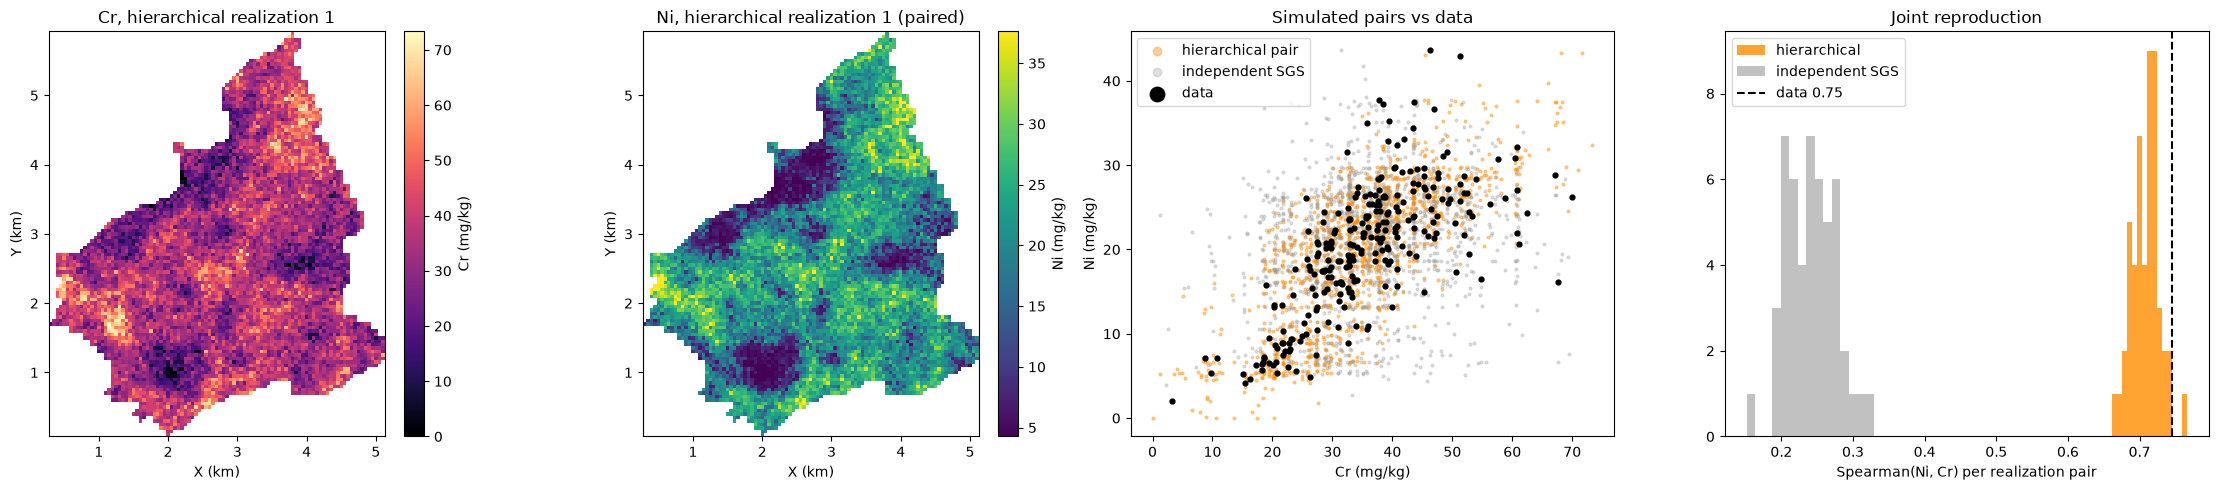

✅ [PASS] hierarchical pairs reproduce the Ni-Cr correlation  data 0.75, simulated 0.71; independent SGS 0.24


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(23, 5))
r = 0
show_map(axes[0], cr_h[r], "Cr, hierarchical realization 1", cmap="magma", label="Cr (mg/kg)")
show_map(axes[1], ni_h[r], "Ni, hierarchical realization 1 (paired)", vmin=vmin, vmax=vmax)
s = np.random.default_rng(1).choice(len(grid), 1500, replace=False)
axes[2].scatter(cr_h[r, s], ni_h[r, s], s=4, alpha=0.4, c="darkorange", label="hierarchical pair")
axes[2].scatter(cr_ind[r, s], ni_ind[r, s], s=4, alpha=0.3, c="0.6", label="independent SGS")
axes[2].scatter(df.Cr, df.Ni, s=12, c="k", label="data")
axes[2].set_xlabel("Cr (mg/kg)")
axes[2].set_ylabel("Ni (mg/kg)")
axes[2].set_title("Simulated pairs vs data")
axes[2].legend(markerscale=3)
axes[3].hist(rc_h, bins=15, alpha=0.8, color="darkorange", label="hierarchical")
axes[3].hist(rc_ind, bins=15, alpha=0.6, color="0.6", label="independent SGS")
axes[3].axvline(rc_data, color="k", ls="--", label=f"data {rc_data:.2f}")
axes[3].set_xlabel("Spearman(Ni, Cr) per realization pair")
axes[3].set_title("Joint reproduction")
axes[3].legend()
plt.tight_layout()
plt.show()

record("hierarchical pairs reproduce the Ni-Cr correlation",
       "PASS" if abs(rc_h.mean() - rc_data) < 0.15 else "FAIL",
       f"data {rc_data:.2f}, simulated {rc_h.mean():.2f}; independent SGS {rc_ind.mean():.2f}")

The hierarchical pairs reproduce the Ni-Cr relation of the data: Spearman correlation 0.71 ± 0.02 per realization pair against 0.75 in the data, and the simulated (Cr, Ni) cloud overlays the data scatter. Two *independent* SGS runs correlate only 0.24. That residual comes from both being conditioned on correlated data, and it vanishes away from the samples. So independent simulation destroys most of the joint structure the data show.

Paired realizations answer joint questions. For example, the probability that **both** Ni > 30 mg/kg and Cr > 45 mg/kg at a node is the fraction of realization pairs where both exceed their threshold. Independent simulations of the two metals would understate it.

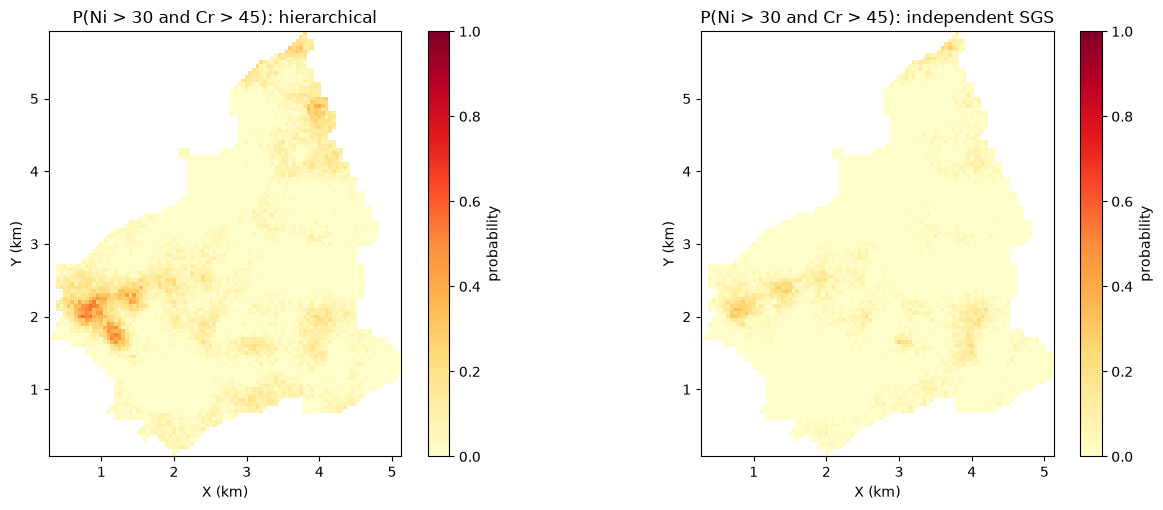

expected area with both above threshold: hierarchical 0.68 km², independent 0.28 km²


In [25]:
p_joint_h = ((ni_h > 30) & (cr_h > 45)).mean(0)
p_joint_ind = ((ni_ind > 30) & (cr_ind > 45)).mean(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
show_map(axes[0], p_joint_h, "P(Ni > 30 and Cr > 45): hierarchical", cmap="YlOrRd", vmin=0, vmax=1,
         label="probability")
show_map(axes[1], p_joint_ind, "P(Ni > 30 and Cr > 45): independent SGS", cmap="YlOrRd", vmin=0, vmax=1,
         label="probability")
plt.tight_layout()
plt.show()
print(f"expected area with both above threshold: hierarchical {p_joint_h.sum() * CELL**2:.2f} km², "
      f"independent {p_joint_ind.sum() * CELL**2:.2f} km²")

***
## Visualization of Spatial Uncertainty

The set of co-simulated realizations measures the uncertainty about the spatial distribution of nickel. Where the realizations agree, nickel is well constrained by the Ni data and the Cr map; where they disagree, it is not. That uncertainty is shown first as an **animation of the realizations**, then summarized by **conditional quantile maps**, and finally turned into a **probability of exceeding a threshold**.

### Animated display of realizations

The first 20 co-simulated realizations in sequence, on one colour scale. Areas that keep their colour are well constrained; areas that flicker carry most of the uncertainty.

In [26]:
N_FRAMES = 20
plt.rcParams["animation.embed_limit"] = 50  # MB
fig_anim, ax_anim = plt.subplots(figsize=(7.2, 7.6))
im_anim = ax_anim.imshow(to_image(cos[0]), origin="lower", extent=EXTENT, cmap="YlOrRd", vmin=vmin, vmax=vmax)
ax_anim.scatter(xy[:, 0], xy[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
plt.colorbar(im_anim, ax=ax_anim, label="Ni (mg/kg)", fraction=0.046, pad=0.04)
ax_anim.set_xlabel("X (km)")
ax_anim.set_ylabel("Y (km)")
title_anim = ax_anim.set_title(f"Co-simulated Ni, realization 1 / {N_FRAMES}")


def _update(frame):
    im_anim.set_data(to_image(cos[frame]))
    title_anim.set_text(f"Co-simulated Ni, realization {frame + 1} / {N_FRAMES}")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=N_FRAMES, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

### Conditional quantile maps (q10, median, q90)

At each node $\mathbf{u}$ the local conditional distribution is the empirical distribution of the $L$ simulated values $\{z^{(\ell)}(\mathbf{u})\}_{\ell=1}^{L}$. The maps show its 0.10, 0.50 and 0.90 quantiles.

**How to read them (Goovaerts, 1997):**

- **High values of the 0.1-quantile map** mark areas where nickel is *certainly large*: even the lower tail of the local distribution is high.
- **Low values of the 0.9-quantile map** mark areas where nickel is *certainly small*: even the upper tail is low.
- Where q10 is low and q90 is high, the local distribution is wide and nickel is poorly constrained.

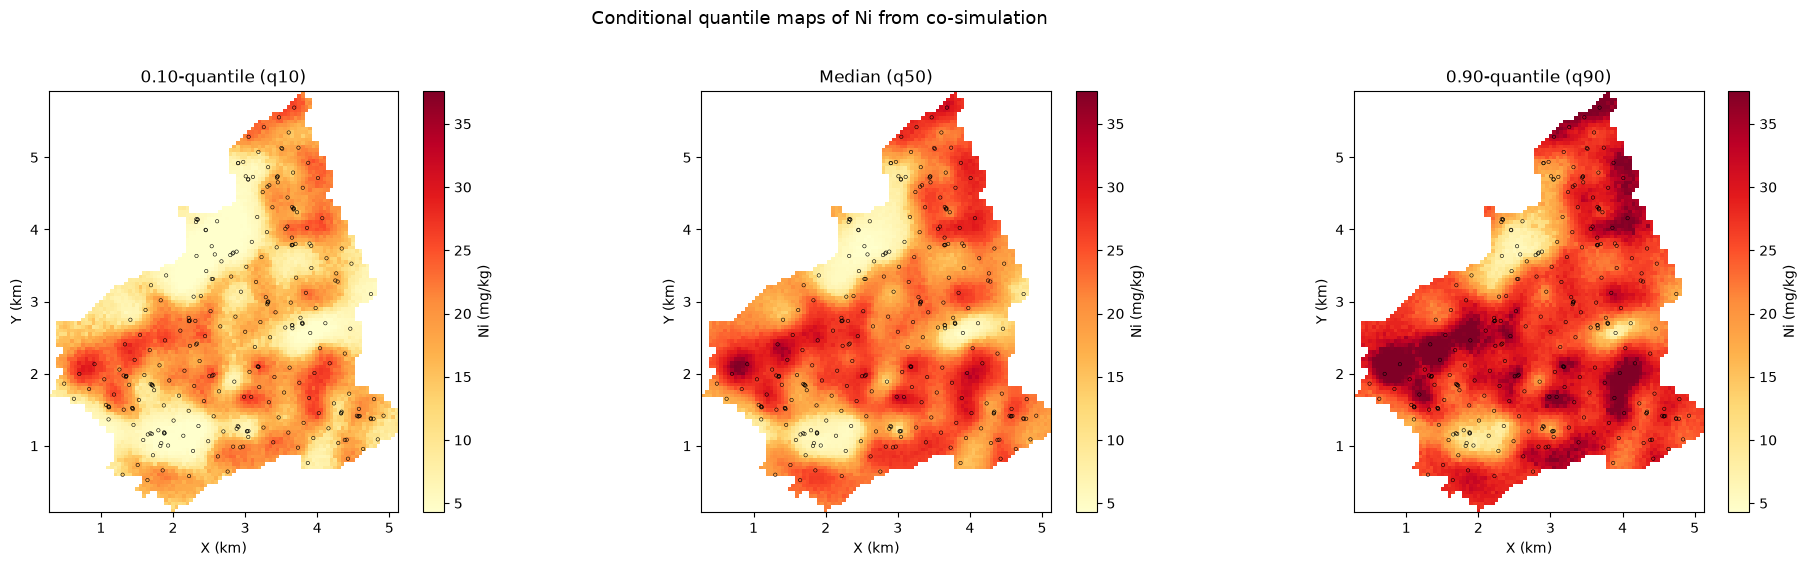

mean width of the 80% interval: co-simulation 11.94 mg/kg, SGS 12.89 mg/kg


In [27]:
q10, q50, q90 = np.quantile(cos, [0.10, 0.50, 0.90], axis=0)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, vals, title in zip(axes, (q10, q50, q90), ("0.10-quantile (q10)", "Median (q50)", "0.90-quantile (q90)")):
    show_map(ax, vals, title, cmap="YlOrRd", vmin=vmin, vmax=vmax, points=xy)
fig.suptitle("Conditional quantile maps of Ni from co-simulation", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

q10s, q90s = np.quantile(sgs_sk, [0.10, 0.90], axis=0)
print(f"mean width of the 80% interval: co-simulation {np.mean(q90 - q10):.2f} mg/kg, SGS {np.mean(q90s - q10s):.2f} mg/kg")

### Probability of exceeding a threshold

The probability that Ni exceeds a threshold $z_c$ at node $\mathbf{u}$ is the fraction of realizations above it,

$$
\Pr\{Z(\mathbf{u}) > z_c\} \approx \frac{1}{L} \sum_{\ell=1}^{L} \mathbf{1}\bigl[z^{(\ell)}(\mathbf{u}) > z_c\bigr].
$$

$z_c = 30$ mg/kg (about the 85th percentile of the data) is used as an illustrative threshold. Because each realization is a full map, the **area** above the threshold has a distribution too, which kriging cannot provide.

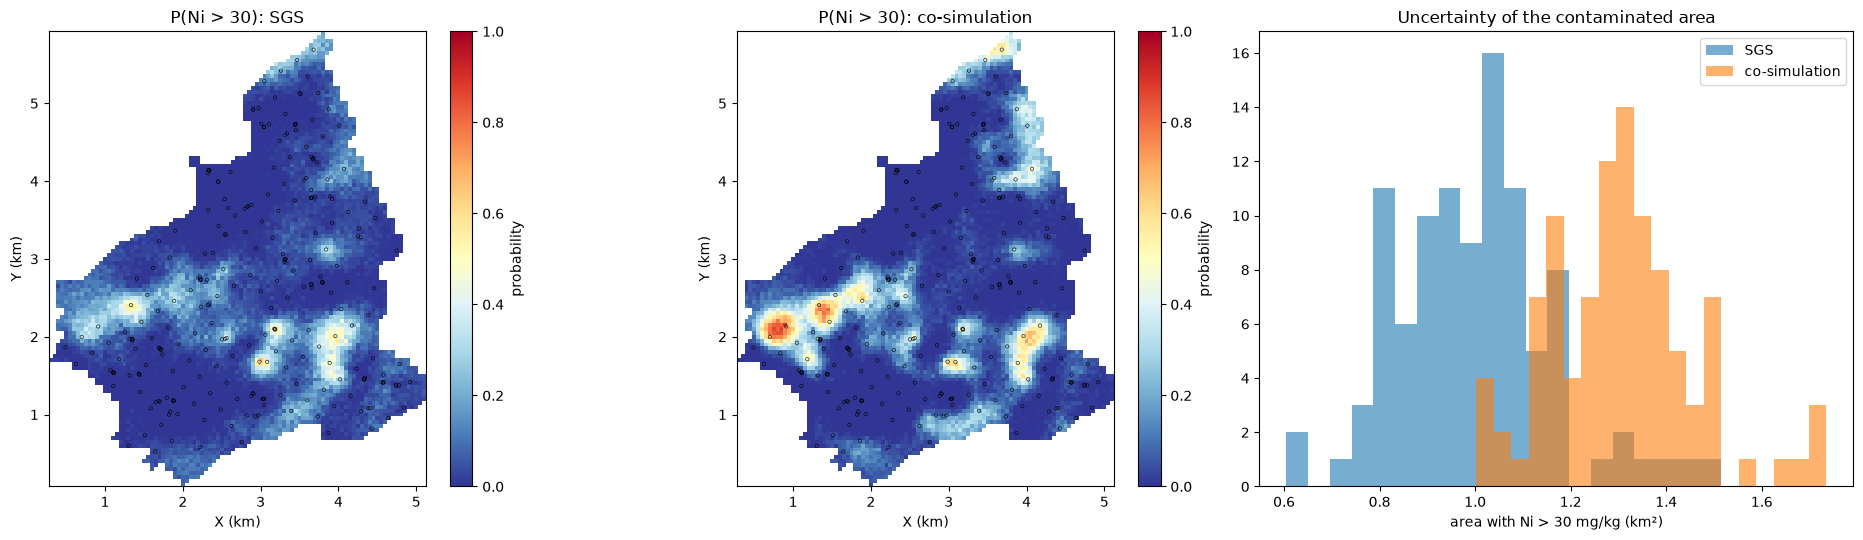

SGS           : area 1.00 km² (80% interval 0.81-1.17); nodes classified with P<0.1 or P>0.9: 75%
co-simulation : area 1.31 km² (80% interval 1.14-1.49); nodes classified with P<0.1 or P>0.9: 73%


In [28]:
ZC = 30.0
p_sgs = (sgs_sk > ZC).mean(0)
p_cos = (cos > ZC).mean(0)
area_sgs = (sgs_sk > ZC).sum(1) * CELL ** 2
area_cos = (cos > ZC).sum(1) * CELL ** 2

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
show_map(axes[0], p_sgs, f"P(Ni > {ZC:.0f}): SGS", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability", points=xy)
show_map(axes[1], p_cos, f"P(Ni > {ZC:.0f}): co-simulation", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability",
         points=xy)
axes[2].hist(area_sgs, bins=20, alpha=0.6, label="SGS")
axes[2].hist(area_cos, bins=20, alpha=0.6, label="co-simulation")
axes[2].set_xlabel(f"area with Ni > {ZC:.0f} mg/kg (km²)")
axes[2].set_title("Uncertainty of the contaminated area")
axes[2].legend()
plt.tight_layout()
plt.show()

for name, a, p in [("SGS", area_sgs, p_sgs), ("co-simulation", area_cos, p_cos)]:
    certain = np.mean((p < 0.1) | (p > 0.9))
    print(f"{name:14s}: area {a.mean():.2f} km² (80% interval {np.quantile(a, .1):.2f}-{np.quantile(a, .9):.2f}); "
          f"nodes classified with P<0.1 or P>0.9: {certain:.0%}")

***
## CPU vs GPU Timing

`GaussianCoSimulator.simulate` runs one realization after another on the CPU. With `use_gpu=True` it runs all realizations at once, one CUDA thread each. The timings below use the full 5,957-node grid, collocated co-simulation with the Cr map, `num_points=16`, and a range of `nsim`. A one-realization warm-up compiles the CUDA kernel before timing. Each configuration is timed once; CPU and GPU realizations are compared for every `nsim`. If no usable GPU is found, the GPU columns stay empty.

 nsim CPU (s) GPU (s) speedup max |GPU-CPU|
    1    0.33    1.87    0.2x       1.6e-13
    8    2.68    2.10    1.3x       1.7e-13
   32   10.70    3.01    3.6x       2.0e-13
  128   42.65    3.53   12.1x       2.0e-13


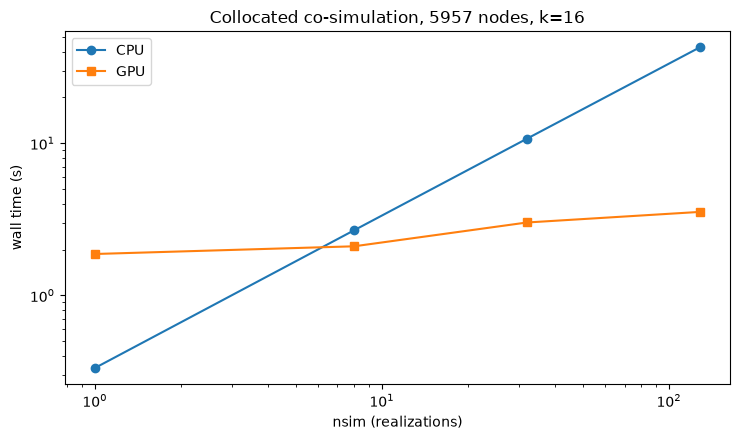

✅ [PASS] GPU co-simulation equals CPU (all nsim)  max diff 2.0e-13 mg/kg; speedup at nsim=128: 12.1x


In [29]:
NSIM_LIST = [1, 8, 32, 128]
cpu_sim = GaussianCoSimulator(vario_ni, num_points=NUM_POINTS, radius=RADIUS, use_gpu=False).fit(
    grid, df, "Xloc", "Yloc", "Ni", secondary=cr_grid, secondary_col="Cr")
gpu_sim = GaussianCoSimulator(vario_ni, num_points=NUM_POINTS, radius=RADIUS, use_gpu=True).fit(
    grid, df, "Xloc", "Yloc", "Ni", secondary=cr_grid, secondary_col="Cr") if USE_GPU else None
if USE_GPU:
    gpu_sim.simulate(nsim=1, seed=0)  # warm-up: kernel compilation
    cp.cuda.Device(0).synchronize()

rows = []
for nsim in NSIM_LIST:
    t0 = time.perf_counter()
    out_cpu = cpu_sim.simulate(nsim=nsim, seed=5)
    row = {"nsim": nsim, "CPU (s)": time.perf_counter() - t0, "GPU (s)": np.nan, "speedup": np.nan,
           "max |GPU-CPU|": np.nan}
    if USE_GPU:
        t0 = time.perf_counter()
        out_gpu = gpu_sim.simulate(nsim=nsim, seed=5)
        cp.cuda.Device(0).synchronize()
        row["GPU (s)"] = time.perf_counter() - t0
        row["speedup"] = row["CPU (s)"] / row["GPU (s)"]
        row["max |GPU-CPU|"] = float(np.abs(out_gpu - out_cpu).max())
    rows.append(row)

bench = pd.DataFrame(rows)
print(bench.to_string(index=False, formatters={"CPU (s)": "{:.2f}".format, "GPU (s)": "{:.2f}".format,
                                               "speedup": "{:.1f}x".format, "max |GPU-CPU|": "{:.1e}".format}))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(bench["nsim"], bench["CPU (s)"], "o-", label="CPU")
if USE_GPU:
    ax.loglog(bench["nsim"], bench["GPU (s)"], "s-", label="GPU")
ax.set_xlabel("nsim (realizations)")
ax.set_ylabel("wall time (s)")
ax.set_title(f"Collocated co-simulation, {len(grid)} nodes, k={NUM_POINTS}")
ax.legend()
plt.tight_layout()
plt.show()
if USE_GPU:
    record("GPU co-simulation equals CPU (all nsim)",
           "PASS" if bench["max |GPU-CPU|"].max() < 1e-6 else "FAIL",
           f"max diff {bench['max |GPU-CPU|'].max():.1e} mg/kg; speedup at nsim={NSIM_LIST[-1]}: "
           f"{bench['speedup'].iloc[-1]:.1f}x")

On the 5,957-node grid (RTX A5500 Laptop GPU in this run; re-running will shift the numbers):

* The CPU engine costs about 0.33 s per realization, so its time grows linearly with `nsim` (43 s for 128).
* The GPU time is nearly flat: about 2 s for one realization and 3.6 s for 128. One thread per realization leaves the GPU mostly idle at small `nsim`, so for `nsim = 1` the GPU is about 5× **slower** than the CPU. The two break even near `nsim = 8`, and at `nsim = 128` the GPU is about 12× faster. The gap keeps growing with `nsim` until the GPU is full.
* The GPU and CPU realizations agree to about $10^{-13}$ mg/kg at every `nsim`: the GPU path changes speed, not results.

Use `use_gpu=True` (or `'auto'`) whenever you need tens of realizations or more. For a single quick realization, the CPU is faster.

***
## Summary and Conclusions

In [30]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,sgsim_gpu: exact conditioning,PASS,max |sim - data| = 0.0e+00
1,sgsim_gpu: realizations vary away from data,PASS,mean std across realizations = 4.47 mg/kg
2,sgsim_gpu: same seed -> identical,PASS,
3,sgsim_gpu: different seed -> different,PASS,
4,sgsim_gpu: GPU = CPU for the same seed,PASS,max |GPU - CPU| = 6.2e-14 mg/kg
5,sgcosim == GaussianCoSimulator(...).simulate (...,PASS,"max diff = 2.5e-13 (sgcosim on CPU, class on GPU)"
6,co-simulation: exact conditioning,PASS,max |sim - data| = 0.0e+00
7,rho = 0 reduces to plain SGS (same seed),PASS,max diff = 0.0e+00
8,co-simulation (rho_map) lowers E-type RMSE vs SGS,PASS,5.67 -> 4.91 mg/kg
9,co-simulation (rho_map) lowers CRPS vs SGS,PASS,3.05 -> 2.61


- **Sequential Gaussian co-simulation** draws the primary at each node from its collocated simple-cokriging distribution under Markov Model 1. It needs only the primary variogram and the correlation $\rho$. $\rho = 0$ gives plain SGS (checked exactly), and $\rho \to 1$ copies the secondary.
- On the **Jura** data, nickel was co-simulated with a kriged chromium map as the exhaustive secondary. Conditioning is exact, the Ni histogram and short-range variogram are reproduced, and the realizations carry the Cr pattern.
- **$\rho$ must match the secondary as used at the nodes.** The correlation with *measured* Cr (0.70) over-weights a kriged map: 80% intervals then cover only 64% of the held-out values. The leave-one-out correlation with the *kriged* map (0.40) gives the lowest error (RMSE 4.91 vs 5.67 mg/kg for SGS, CRPS 2.61 vs 3.05) with well-calibrated intervals (coverage 0.85). A scan over $\rho$ puts the optimum at the same place.
- **`mm1_nugget_ratio_`** correctly flagged the kriged map as too smooth for multi-collocated cokriging, which performed worse than the collocated default.
- **`sgcosim_hierarchical`** reproduces the Ni-Cr correlation when Cr is known only at the data (0.71 vs 0.75). Independent simulations do not (0.24), and they underestimate joint exceedance areas (0.28 vs 0.68 km² with both Ni > 30 and Cr > 45 mg/kg).
- The realizations turn into **uncertainty maps**: conditional quantiles, exceedance probabilities, and the distribution of the area with Ni > 30 mg/kg. Co-simulation shifts that area estimate (1.31 vs 1.00 km² for SGS) because the Cr map raises Ni away from the Ni samples.
- **GPU:** `use_gpu=True` and `sgsim_gpu` run one CUDA thread per realization and reproduce the CPU realizations to about $10^{-13}$. They are slower than the CPU for one realization and about 12× faster at 128 realizations on this grid.


| Object | Role in this notebook |
|---|---|
| `GaussianCoSimulator` | Collocated / multi-collocated co-simulation engine: `fit` (transform, neighbourhoods, `rho_`, `mm1_nugget_ratio_`), `simulate` (CPU or GPU, `back_transform`) |
| `sgcosim` | One-call co-simulation with an exhaustive secondary (kriged Cr map) |
| `sgcosim_hierarchical` | Joint Ni-Cr simulation when Cr is known only at the data |
| `sgsim_gpu` | Plain SGS baseline on the same engine, one CUDA thread per realization |
| `nscore_forward` | Normal scores for the variogram and $\rho$ |
| `Variogram` / `OrdinaryKriging` | Kriged Cr map used as the exhaustive secondary |

### Choosing the options

| Situation | Choice |
|---|---|
| Secondary known everywhere and smooth (kriged map, DEM, seismic); `mm1_nugget_ratio_` well below 1 | `sgcosim` / `GaussianCoSimulator`, `secondary_neighbors=1` |
| Secondary known everywhere but noisy; `mm1_nugget_ratio_` near or above 1 | `secondary_neighbors > 1` (CPU only) |
| Secondary known only at the data | `sgcosim_hierarchical` |
| No secondary | `sgsim_gpu` (or `sgsim` for octant search) |
| Many realizations, GPU available | `use_gpu=True`: same realizations, much faster |
| Trend in the mean, no secondary | `kriging_type="ordinary"` (watch the variance of the realizations) |

***
## References

| Reference | Used for |
|---|---|
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura case study, undersampled design, quantile maps, co-simulation |
| Xu, W., Tran, T.T., Srivastava, R.M. & Journel, A.G. (1992). Integrating seismic data in reservoir modeling: the collocated cokriging alternative. SPE 24742. | Collocated cokriging |
| Almeida, A.S. & Journel, A.G. (1994). Joint simulation of multiple variables with a Markov-type coregionalization model. *Mathematical Geology* 26, 565-588. | Markov Model 1, hierarchical co-simulation |
| Journel, A.G. (1999). Markov models for cross-covariances. *Mathematical Geology* 31, 955-964. | MM1 and its implied secondary covariance |
| Deutsch, C.V. & Journel, A.G. (1998). *GSLIB: Geostatistical Software Library and User's Guide*, 2nd ed. Oxford University Press. | `sgsim`, variogram conventions, normal-score transform |
| Deutsch, C.V. (1997). Direct assessment of local accuracy and precision. In Baafi, E.Y. & Schofield, N.A. (eds.), *Geostatistics Wollongong '96*, 115-125. Kluwer. | Accuracy plot |
| Gneiting, T. & Raftery, A.E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association* 102, 359-378. | CRPS |